# Upwelling Indices Comparison (v4: everything per metre of coastline)

Copy of `v3.UI_comparison`, with CUTI from `v3.Higher_resolution_cuti` (`CUTI_BEUTI_HR_L.nc`):

1. **CUTI = U^Ek + U^Geo, both in divergence form** (area integral over the band boxes of each row ÷ coastline length L). `CUTI`, `U_ek`, `UGEO` and `BEUTI` below are read directly from the file.
2. **CROCO reference divided by the same L**: `W_L` = (sum of W × box area over the band boxes of each row) / L, instead of band-mean W × 111 km.
   Every row is per metre of coastline; regional (5–16°S) means are plain row means, as in `v3.Higher_resolution_cuti`.
3. **Band = 12 boxes incl. the coast box** (`round(mask_km/Δx)` boxes, ~109 km edge to edge), also for Chl, SST and u.

In [140]:
mask_km = 109
print(mask_km)

109


In [141]:
import xarray as xr
import numpy as np
from scipy.ndimage import binary_erosion, binary_dilation
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.floating_axes as FA
import mpl_toolkits.axisartist.grid_finder as GF
import datetime
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle


In [142]:
def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells + 1, 0)   # v4: n_cells boxes in total, coast box included
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask

In [143]:
def seasonality(data):    
    season = data.groupby('time.month').mean(dim='time')
    return season

## Dataset

In [144]:
lat1,lat0 = -16,-5
path0 = '/gxfs_work/geomar/smomw662/NHCS/notebooks/monthly/'
# Select coastal points by REAL latitude (the old swap_dims collapsed lat to
# 11 phantom points 0..10); average over coast_point, not the broken 'lat'.
_tau = xr.open_dataset('../data/Winds_components_Lu.nc').tau_alongshore
_latc = _tau.lat.mean('offshore')
t_along = _tau.mean(dim='offshore').where((_latc >= lat1) & (_latc <= lat0), drop=True)
t_along

<xarray.DataArray 'tau_alongshore' (time: 432, coast_point: 134)> Size: 463kB
array([[0.05657707, 0.04826033, 0.05814369, ..., 0.03282552, 0.03398016,
        0.03539143],
       [0.04845767, 0.04312579, 0.05148978, ..., 0.02091777, 0.02155974,
        0.02240733],
       [0.04499081, 0.03963697, 0.04591431, ..., 0.01750821, 0.01762873,
        0.01785168],
       ...,
       [0.08513057, 0.07089712, 0.08593922, ..., 0.06500588, 0.06600709,
        0.06726992],
       [0.0815278 , 0.06884525, 0.08413419, ..., 0.06768828, 0.0691054 ,
        0.07086711],
       [0.07410591, 0.06182153, 0.0748501 , ..., 0.05743211, 0.05820201,
        0.05921074]])
Coordinates:
  * time         (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * coast_point  (coast_point) int64 1kB 51 52 53 54 55 ... 180 181 182 183 184
    bearing      (coast_point) float64 1kB 135.0 161.6 135.0 ... 90.0 90.0 90.0

In [145]:
# high-resolution CUTI (one lat_band per 1/12 deg grid row); the file is stored N -> S,
# sort S -> N so the slice runs (lat1, lat0) = (-16, -5)
hr = xr.open_dataset('../data/CUTI_BEUTI_HR_L_C.nc').sortby('lat_band').compute().sel(lat_band=slice(lat1, lat0))
assert int(hr.L_coast.isnull().sum()) == 0

# every row is already per metre of coastline (divided by its own L);
# 5-16S means below are plain row means, as in v3.Higher_resolution_cuti

# CUTI from v3.Higher_resolution_cuti: U_ek and UGEO in divergence form

# CROCO reference, m2/s: per row (area integral of W) / L, then the row mean
WMLD_L = hr.W_L.mean('lat_band').rename('W_MLD')
CUTI    = hr.CUTI
BEUTI   = hr.BEUTI
ugeo    = hr.UGEO      # u_geo (velocity) is not stored in CUTI_BEUTI_HR_L.nc
UGEO    = hr.UGEO

In [146]:
CUI = xr.open_dataset('../data/CUI.nc').compute().sel(lat=slice(lat1,lat0))
CUI

<xarray.Dataset> Size: 468kB
Dimensions:  (time: 432, lat: 134)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat      (lat) float64 1kB -15.95 -15.87 -15.79 ... -5.242 -5.159 -5.076
Data variables:
    CUI_cc   (time, lat) float64 463kB 2.378 2.615 2.373 ... 1.914 1.983 2.028

In [147]:
u = xr.open_dataset('../data/UV_velocities.nc').compute().transpose('time','lat','lon')
u = u.where(u!=0,np.nan)
mask = coastal_band_mask(u,'u', mask_km).sel(lon=slice(-85,None),lat=slice(lat1,lat0))
u = u.where(mask).u

In [148]:
#Chlorphyll
CHL = xr.open_dataset('../data/Chlorophyll_CROCO.nc').drop_vars('s_rho').compute()
CHL = CHL.where(mask).sel(lon=slice(-85,None),lat=slice(lat1,lat0))
CHL['time'] = CUI.time
CHL

<xarray.Dataset> Size: 90MB
Dimensions:  (time: 432, lat: 134, lon: 194)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87
  * lat      (lat) float64 1kB -15.95 -15.87 -15.79 ... -5.242 -5.159 -5.076
Data variables:
    chla     (time, lat, lon) float64 90MB nan nan nan nan ... nan nan nan nan

In [149]:
## CROCO
wmld = xr.open_dataset('../data/W_mld_Croco.nc').compute()
mask = coastal_band_mask(wmld,'WMLD', mask_km)
wmld = wmld.where(mask).sel(lon=slice(-85,None),lat=slice(lat1,lat0))
wmld

<xarray.Dataset> Size: 90MB
Dimensions:  (time: 432, lat: 134, lon: 194)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lon      (lon) float64 2kB -84.95 -84.87 -84.78 ... -69.03 -68.95 -68.87
  * lat      (lat) float64 1kB -15.95 -15.87 -15.79 ... -5.242 -5.159 -5.076
Data variables:
    WMLD     (time, lat, lon) float64 90MB nan nan nan nan ... nan nan nan nan

## Seasonality

### Seasonality paper plot

In [150]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import MultipleLocator


def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

In [151]:
import datetime

NINO = [
    (datetime.datetime(1982, 6, 1), datetime.datetime(1983, 12, 31)),
    (datetime.datetime(1997, 4, 1), datetime.datetime(1998, 7, 31)),
]

def keep_en_events(da, en_windows=NINO, dim='time'):
    """Mask out El Niño periods from a time series."""
    mask = np.zeros(da.sizes[dim], dtype=bool)
    time = da[dim].values
    for start, end in en_windows:
        start64 = np.datetime64(start)
        end64   = np.datetime64(end)
        mask |= ((time >= start64) & (time <= end64))
    return da.isel({dim: mask})


def drop_en_events(da, en_windows=NINO, dim='time'):
    """Mask out El Niño periods from a time series."""
    mask = np.ones(da.sizes[dim], dtype=bool)
    time = da[dim].values
    for start, end in en_windows:
        start64 = np.datetime64(start)
        end64   = np.datetime64(end)
        mask &= ~((time >= start64) & (time <= end64))
    return da.isel({dim: mask})

## Interannual statistics — `Table2_ci_intervals` method (padding = 0)

Every interannual series and every Pearson $r$ / $r^2$ / $p$ below is computed as in `Table2_ci_intervals.ipynb`:

1. area mean → monthly anomalies (climatology removed) → **linear detrend**
2. 13-month centred running mean on the continuous series (NaN edges trimmed)
3. El Niño 06/1982–12/1983 and 04/1997–07/1998 masked **after** smoothing, **no pad** (`PAD = 0`; months set to NaN, not deleted)
4. Pearson $r$ on the valid pairs; gap-aware autocorrelation of both series
5. e-folding times τx, τy; τ_eff = 2τxτy/(τx+τy); N_eff = N/τ_eff
6. Fisher-z 95% CI with N_eff − 3; t-test (H0: ρ = 0) with N_eff − 2 dof → the $p$ shown on the plots

X = W_MLD, Y = index. CROCO_j is no longer used: every index is compared with the band-mean W_MLD.

In [152]:
from scipy import stats

PAD = 0   # El Nino padding (months) -- no padding

# Extreme El Nino windows (masked AFTER smoothing, with a pad on each side)
NINO = [
    (pd.Timestamp('1982-06-01'), pd.Timestamp('1983-12-31')),
    (pd.Timestamp('1997-04-01'), pd.Timestamp('1998-07-31')),
]


# ----------------------------------------------------------------------------- helpers
def _to_series(obj, name=None):
    """Dataset/DataArray -> 1-D monthly series (mean over every dim except time).
    The time axis is put on month starts so series with different stamps
    (15th, end of month, cftime, ...) line up month by month."""
    if isinstance(obj, xr.Dataset):
        dvars = list(obj.data_vars)
        if len(dvars) != 1:
            raise ValueError(f'Dataset has {len(dvars)} variables {dvars}; '
                             'pass the DataArray you want, e.g. ds["chla"].')
        obj = obj[dvars[0]]
    other = [d for d in obj.dims if d != 'time']
    da = obj.mean(dim=other) if other else obj
    months = pd.to_datetime(da['time'].dt.strftime('%Y-%m-01').values)
    da = da.assign_coords(time=months)
    da = da.drop_vars([c for c in da.coords if c != 'time'])
    da.name = name or obj.name or 'series'
    return da


def _anomalies(da):
    """Remove the mean seasonal cycle (monthly climatology)."""
    clim = da.groupby('time.month').mean('time')
    return (da.groupby('time.month') - clim).drop_vars('month', errors='ignore')


def _detrend(da):
    """Remove a least-squares linear trend."""
    t = np.arange(da.sizes['time'], dtype=float)
    y = da.values.astype(float)
    ok = np.isfinite(y)
    b, a = np.polyfit(t[ok], y[ok], 1)
    return da - (a + b * t)


def acf_gaps(x, nlags):
    """Sample autocorrelation that tolerates NaN gaps.
    rho(k) = sum_i m_i m_{i+k} x_i x_{i+k} / sum_i m_i x_i^2   (x demeaned, m_i = 1 if valid)
    Pairs keep their true time separation; with no gaps this equals statsmodels acf(adjusted=False)."""
    x = np.asarray(x, float)
    x = x - np.nanmean(x)
    denom = np.nansum(x ** 2)
    out = np.empty(nlags + 1)
    for k in range(nlags + 1):
        a, b = x[:len(x) - k], x[k:]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out[k] = np.sum(a[ok] * b[ok]) / denom
    return out


def _efolding(acf, thr):
    """First lag at which the autocorrelation drops below thr (1/e -> e-folding time)."""
    below = np.where(acf < thr)[0]
    if below.size == 0:
        raise ValueError('ACF never drops below the threshold; increase nlags.')
    return int(below[0])


def _en_mask(time, windows=NINO, pad_months=PAD):
    t = pd.DatetimeIndex(time.values)
    pad = pd.DateOffset(months=pad_months)
    m = np.zeros(t.size, dtype=bool)
    for s, e in windows:
        m |= (t >= s - pad) & (t <= e + pad)
    return m


def _trim_edges(da_x, da_y):
    """Drop only the leading/trailing NaNs left by the running mean (interior gaps stay)."""
    ok = np.where(np.isfinite(da_x.values) & np.isfinite(da_y.values))[0]
    sl = slice(ok[0], ok[-1] + 1)
    return da_x.isel(time=sl), da_y.isel(time=sl)


# ----------------------------------------------------------------------------- main
def ci_intervals(x, y, x_name=None, y_name=None, window=13, pad_months=PAD,
                 exclude_en=True, thr=1 / np.e, nlags=100, conf=0.95,
                 plot=False, verbose=False):
    """Correlation of two monthly series with a CI corrected for autocorrelation
    (Table2_ci_intervals). Besides the statistics, the dict also returns the
    smoothed series (x_sm, y_sm, NOT masked), their time axis t, the El Nino
    mask en and the pairs used for r (valid), for the scatter plots."""
    xs = _to_series(x, x_name)
    ys = _to_series(y, y_name)
    xn, yn = xs.name, ys.name
    xs, ys = xr.align(xs, ys, join='inner')
    if xs.sizes['time'] < 3 * window:
        raise ValueError(f'Only {xs.sizes["time"]} common months between {xn} and {yn}; '
                         'check the time axes.')

    # 1) anomalies + detrend (monthly, full record)
    x_dt = _detrend(_anomalies(xs))
    y_dt = _detrend(_anomalies(ys))

    # 2) running mean on the continuous series, trim the NaN edges
    x_sm = x_dt.rolling(time=window, center=True).mean()
    y_sm = y_dt.rolling(time=window, center=True).mean()
    x_sm, y_sm = _trim_edges(x_sm, y_sm)

    # 3) mask El Nino AFTER smoothing (NaN in place, nothing deleted)
    en = _en_mask(x_sm.time, pad_months=pad_months) if exclude_en else np.zeros(x_sm.sizes['time'], bool)
    xv = np.where(en, np.nan, x_sm.values)
    yv = np.where(en, np.nan, y_sm.values)
    valid = np.isfinite(xv) & np.isfinite(yv)
    xv[~valid] = np.nan
    yv[~valid] = np.nan

    # 4) statistics
    N = int(valid.sum())
    rho_hat = float(np.corrcoef(xv[valid], yv[valid])[0, 1])
    acf_x = acf_gaps(xv, nlags)
    acf_y = acf_gaps(yv, nlags)
    tau_x = _efolding(acf_x, thr)
    tau_y = _efolding(acf_y, thr)
    tau_eff = 2 * tau_x * tau_y / (tau_x + tau_y)
    N_eff = N / tau_eff

    if N_eff > 3:
        z = np.arctanh(rho_hat)
        se = 1 / np.sqrt(N_eff - 3)
        zc = stats.norm.ppf((1 + conf) / 2)
        ci = np.tanh([z - zc * se, z + zc * se])
    else:
        ci = np.array([np.nan, np.nan])
    dof = N_eff - 2
    t_stat = abs(rho_hat) * np.sqrt(dof / (1 - rho_hat ** 2))
    p = float(2 * stats.t.sf(t_stat, dof))

    res = dict(x=xn, y=yn, exclude_en=exclude_en, pad_months=pad_months,
               N=N, n_masked=int(en.sum()), tau_x=tau_x, tau_y=tau_y,
               tau_eff=tau_eff, N_eff=N_eff, rho_hat=rho_hat,
               ci=ci, ci_low=ci[0], ci_high=ci[1], p=p, R2=rho_hat ** 2,
               t=pd.DatetimeIndex(x_sm.time.values), x_sm=x_sm.values, y_sm=y_sm.values,
               en=en, valid=valid)

    if verbose:
        print(f'{xn} vs {yn}  (El Nino {"excluded, pad " + str(pad_months) + " mo" if exclude_en else "included"})')
        print(f'  N={N}  tau_x={tau_x}  tau_y={tau_y}  tau_eff={tau_eff:.1f}  N_eff={N_eff:.1f}')
        print(f'  r={rho_hat:.3f}  {int(conf*100)}% CI=[{ci[0]:.2f}, {ci[1]:.2f}]  '
              f'R2={rho_hat**2:.2f}  p={p:.2g}')

    # 5) plots
    if plot:
        fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(11, 8),
                                       gridspec_kw=dict(height_ratios=[1.2, 1]))
        if exclude_en:
            pad = pd.DateOffset(months=pad_months)
            for i, (s, e) in enumerate(NINO):
                ax1.axvspan(s - pad, e + pad, color='0.9', zorder=0,
                            label=f'masked (EN +/- {pad_months} mo)' if i == 0 else None)
                ax1.axvspan(s, e, color='0.75', zorder=0,
                            label='El Nino' if i == 0 else None)
        ax1.plot(x_dt.time, x_dt, color='C0', lw=0.6, alpha=0.35)
        ax1.plot(x_sm.time, xv, color='C0', lw=2, label=f'{xn}')
        ax1.axhline(0, color='k', lw=0.5)
        ax1.set_ylabel(xn, color='C0')
        ax2 = ax1.twinx()
        ax2.plot(y_dt.time, y_dt, color='C1', lw=0.6, alpha=0.35)
        ax2.plot(y_sm.time, yv, color='C1', lw=2, label=f'{yn}')
        ax2.set_ylabel(yn, color='C1')
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)
        ax1.set_title(f'Detrended anomalies (thin: monthly, bold: {window}-month mean used for r)')

        lags = np.arange(nlags + 1)
        ax3.plot(lags, acf_x, color='C0', label=xn)
        ax3.plot(lags, acf_y, color='C1', label=yn)
        ax3.axhline(thr, color='k', lw=0.8, label='1/e' if np.isclose(thr, 1 / np.e) else f'{thr:.2f}')
        ax3.axhline(0, color='k', lw=0.5)
        ax3.axvline(tau_x, color='C0', ls='--', lw=1)
        ax3.axvline(tau_y, color='C1', ls='--', lw=1)
        ax3.set_xlabel('lag [months]')
        ax3.set_ylabel('autocorrelation')
        ax3.legend(fontsize=8)
        ax3.set_title(f'tau_x={tau_x}, tau_y={tau_y}, tau_eff={tau_eff:.1f}, N={N}, N_eff={N_eff:.1f} | '
                      f'r={rho_hat:.2f}, CI=[{ci[0]:.2f}, {ci[1]:.2f}], p={p:.1g}', fontsize=9)
        fig.tight_layout()
        plt.show()

    return res


# ----------------------------------------------------------------------------- v3 helpers
def prep_ia(da, exclude_en=False, pad_months=PAD, window=13, name=None):
    """One series through steps 1-3 of ci_intervals (anomalies -> detrend ->
    13-month centred mean, edges trimmed -> El Nino set to NaN if exclude_en).
    Used for the interannual time-series plots and spread statistics."""
    s = _to_series(da, name)
    sm = _detrend(_anomalies(s)).rolling(time=window, center=True).mean().dropna('time')
    if exclude_en:
        sm = sm.where(~_en_mask(sm.time, pad_months=pad_months))
    return sm


def ia_pair(x, y, exclude_en=True):
    """ci_intervals(x, y) plus the El Nino masks per event for the scatter colours.
    Returns res, x, y, en1, en2 (x/y: smoothed detrended anomalies, all months)."""
    res = ci_intervals(x, y, pad_months=PAD, exclude_en=exclude_en)
    t = res['t']
    en1 = np.asarray((t >= NINO[0][0]) & (t <= NINO[0][1]))
    en2 = np.asarray((t >= NINO[1][0]) & (t <= NINO[1][1]))
    return res, res['x_sm'], res['y_sm'], en1, en2


def _ptxt(pv):
    return "$p$ < 0.001" if pv < 0.001 else f"$p$ = {pv:.3f}"


def rp_label(res):
    """r^2 / p box text (p from the N_eff t-test)."""
    return f"$r^2$ = {res['R2']:.2f}\n{_ptxt(res['p'])}"


def print_res(name, res):
    print(f"{name:28s} r = {res['rho_hat']:+.3f}  95% CI = [{res['ci_low']:+.2f}, {res['ci_high']:+.2f}]  "
          f"r2 = {res['R2']:.2f}  p = {res['p']:.2g}  N = {res['N']}  N_eff = {res['N_eff']:.1f}")

In [153]:
# def taylor_skill(std_norm, corr):
#     return (4 * (1 + corr)**4) / ((std_norm + 1/std_norm)**2 * (1 + 1)**4)

def lagged_correlation(test, ref, max_lag=6):
    """
    Find the lag (in months) that maximizes |Pearson correlation|.
    Positive lag: test lags reference (test responds after ref).
    Negative lag: test leads reference.
    """
    t = np.asarray(test).ravel()
    r = np.asarray(ref).ravel()
    mask = np.isfinite(t) & np.isfinite(r)
    t, r = t[mask], r[mask]

    lags = np.arange(-max_lag, max_lag + 1)
    corrs = []
    for lag in lags:
        if lag < 0:
            # test leads: shift test forward
            tt, rr = t[:lag], r[-lag:]
        elif lag > 0:
            # test lags: shift test backward
            tt, rr = t[lag:], r[:-lag]
        else:
            tt, rr = t, r
        corrs.append(np.corrcoef(tt, rr)[0, 1])

    corrs = np.array(corrs)
    # Pick the lag with maximum absolute correlation (handles anti-correlation)
    best_idx = np.argmax(np.abs(corrs))
    return lags[best_idx], corrs[best_idx]

In [154]:
wmlds  = seasonality(WMLD_L)
CUTIs  = seasonality(CUTI).mean(dim=('lat_band'))
BEUTIs = seasonality(BEUTI).mean(dim=('lat_band'))
CUIs   = seasonality(CUI.CUI_cc).mean(dim='lat')
CHLs   = seasonality(CHL.chla).mean(dim=('lat', 'lon'))

In [155]:
# Group 1: Dynamical indices (same units as W_mld)
dynamical_pairs = {
    'CUTI': (CUTIs,  wmlds),
}

# Group 2: Proxy indices (correlation only)
proxy_pairs = {
    'BEUTI': (BEUTIs, wmlds),
    'CUI':   (CUIs,   wmlds),
    'Chl':   (CHLs,   wmlds),
}

In [156]:
## for Winds
from scipy.stats import pearsonr, spearmanr

dyn_rows = []
for name, (test, ref) in dynamical_pairs.items():
    t = test.values.ravel()
    r = ref.values.ravel()
    mask = np.isfinite(t) & np.isfinite(r)
    t, r = t[mask], r[mask]
    pearson, _ = pearsonr(t, r)
    dyn_rows.append({
        'name':    name,
        'pearson': pearson,
    })

dyn_df = pd.DataFrame(dyn_rows).set_index('name').sort_values('pearson', ascending=False)
print("=== Dynamical indices ===")
print(dyn_df.round(3))


# --- Proxy indices with lag ---
proxy_rows = []
for name, (test, ref) in proxy_pairs.items():
    t = test.values.ravel()
    r = ref.values.ravel()
    mask = np.isfinite(t) & np.isfinite(r)
    t, r = t[mask], r[mask]

    pearson_0  = pearsonr(t, r)[0]
    spearman_0 = spearmanr(t, r)[0]
    best_lag, best_corr = lagged_correlation(t, r, max_lag=5)

    proxy_rows.append({
        'name':         name,
        'pearson':      pearson_0,
        'spearman':     spearman_0,
        'best_lag_mo':  best_lag,
        'corr_at_lag':  best_corr,
    })

proxy_df = pd.DataFrame(proxy_rows).set_index('name')
print("\n=== Proxy indices ===")
print(proxy_df.round(3))


=== Dynamical indices ===
      pearson
name         
CUTI    0.993

=== Proxy indices ===
       pearson  spearman  best_lag_mo  corr_at_lag
name                                              
BEUTI    0.994     0.979            0        0.994
CUI     -0.147    -0.280            3       -0.958
Chl     -0.882    -0.853            1       -0.965


In [157]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import MultipleLocator


def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)


# d = (1/12) * 10 * 111 * 1000

# ============================================================
# Seasonal cycles
# ============================================================
wmlds   = seasonality(WMLD_L)
CUTIs   = seasonality((CUTI)).mean(dim=('lat_band')) 
UGEOs   = seasonality((UGEO)).mean(dim=('lat_band'))
BEUTIs  = seasonality((BEUTI)).mean(dim=('lat_band'))
CUIs    = seasonality((CUI.CUI_cc)).mean(dim='lat')
CHLs    = seasonality((CHL.chla)).mean(dim=('lat', 'lon'))

months = ['J','F','M','A','M','J','J','A','S','O','N','D']


def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)



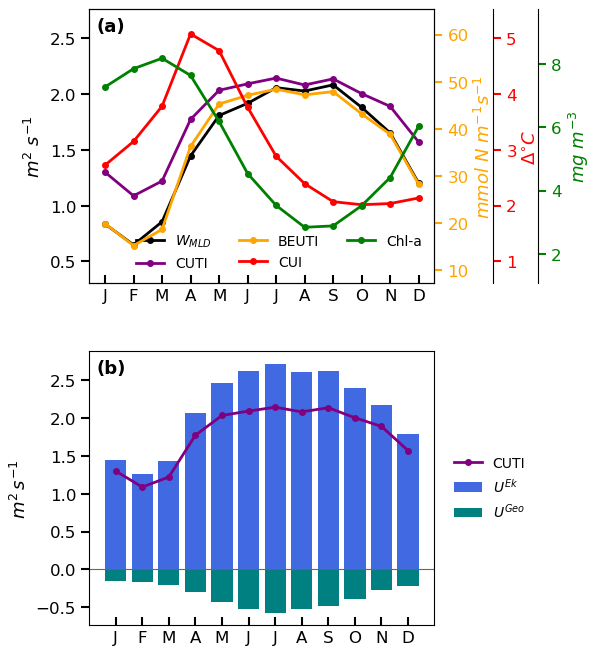

1.53465352831933
1.7780817634877746
36.33747839912183
3.068309194455271
5.406735257338071

Seasonal cycle:   U_ek    U_geo    CUTI   offset
  Jan          +1.45   -0.15   +1.30     10 %
  Feb          +1.26   -0.17   +1.09     14 %
  Mar          +1.43   -0.21   +1.22     15 %
  Apr          +2.07   -0.30   +1.77     14 %
  May          +2.47   -0.43   +2.03     18 %
  Jun          +2.62   -0.53   +2.09     20 %
  Jul          +2.72   -0.57   +2.14     21 %
  Aug          +2.61   -0.53   +2.08     20 %
  Sep          +2.62   -0.49   +2.14     19 %
  Oct          +2.39   -0.39   +2.00     16 %
  Nov          +2.17   -0.28   +1.89     13 %
  Dec          +1.79   -0.22   +1.57     12 %
austral summer (DJF): U_ek = +1.50, U_geo = -0.18 m2/s, offset 12 %
austral winter (JJA): U_ek = +2.65, U_geo = -0.55 m2/s, offset 21 %
largest offset in Jul (21 %), largest |U_geo| in Jul (-0.57 m2/s)


In [158]:
# ============================================================
# Seasonal cycles
# ============================================================
wmlds  = seasonality(WMLD_L)
CUTIs  = seasonality(CUTI).mean(dim=('lat_band'))
BEUTIs = seasonality(BEUTI).mean(dim=('lat_band'))
CUIs   = seasonality(CUI.CUI_cc).mean(dim='lat')
CHLs   = seasonality(CHL.chla).mean(dim=('lat', 'lon'))

months = ['J','F','M','A','M','J','J','A','S','O','N','D']

# Annual means — ylim will be set to mean ± 100% of mean
wmld_mean  = float(wmlds.mean('month'))
cuti_mean  = float(CUTIs.mean('month'))
beuti_mean = float(BEUTIs.mean('month'))
cui_mean   = float(CUIs.mean('month'))
chl_mean   = float(CHLs.mean('month'))

def sym_lim(mean, factor=0.80):
    hw = abs(mean) * factor
    return (mean - hw, mean + hw)

# ============================================================
# Single-panel figure — host: WMld + CUTI; par1: BEUTI; par2: CUI; par3: CHL
# ============================================================
# (b) below: U^Ek and U^Geo magnitudes, see the end of the cell
fig, (ax, axb) = plt.subplots(2, 1, figsize=(6, 8))

par1 = ax.twinx()   # BEUTI
par2 = ax.twinx()   # CUI
par3 = ax.twinx()   # CHL

par2.spines["right"].set_position(("axes", 1.17))
par3.spines["right"].set_position(("axes", 1.30))
for p in (par2, par3):
    make_patch_spines_invisible(p)
    p.spines["right"].set_visible(True)

l1, = ax.plot(wmlds.month,    wmlds,  color='black',  lw=2, marker='o', ms=4, label='$W_{MLD}$')
l2, = ax.plot(CUTIs.month,    CUTIs,  color='purple', lw=2, marker='o', ms=4, label='CUTI')
l3, = par1.plot(BEUTIs.month, BEUTIs, color='orange', lw=2, marker='o', ms=4, label='BEUTI')
l4, = par2.plot(CUIs.month,   CUIs,   color='red',    lw=2, marker='o', ms=4, label='CUI')
l5, = par3.plot(CHLs.month,   CHLs,   color='green',  lw=2, marker='o', ms=4, label='Chl-a')

# ylim: each axis spans ±100% of its annual mean
ax.set_ylim(sym_lim(wmld_mean))
par1.set_ylim(sym_lim(beuti_mean))
par2.set_ylim(sym_lim(cui_mean))
par3.set_ylim(sym_lim(chl_mean))

ax.set_ylabel('$m^{2} \ s^{-1}$',                  fontsize=13, color='black')
par1.set_ylabel('$mmol\ N \ m^{-1} s^{-1}$' , fontsize=13, color='orange')
par2.set_ylabel('$\Delta ^{\circ}C$',                   fontsize=13, color='red')
par3.set_ylabel('$mg \ m^{-3}$',               fontsize=13, color='green')

tkw = dict(size=6, width=1.5)
ax.tick_params(axis='y',   colors='black',  labelsize=12, **tkw)
par1.tick_params(axis='y', colors='orange', labelsize=12, **tkw)
par2.tick_params(axis='y', colors='red',    labelsize=12, **tkw)
par3.tick_params(axis='y', colors='green',  labelsize=12, **tkw)
ax.tick_params(axis='x', labelsize=12, direction='in', **tkw)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(months, fontsize=12)
# ax.grid(True, color='lightgrey')
ax.set_axisbelow(True)

ax.legend(handles=[l1, l2, l3, l4, l5], fontsize=10, ncol=3, frameon=False, loc='lower right')

# ============================================================
# (b) Magnitudes of U^Ek and U^Geo, seasonal cycle (5S-16S row means, HR CUTI file):
#     monthly climatologies, U^Ek (up) and U^Geo (down) as bars, CUTI = U^Ek + U^Geo as a line
# ============================================================
C_EK, C_GEO, C_CUTI = 'royalblue', 'teal', 'purple'   # as in the combined plot (comp_style)
MON3 = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

ek_ts   = hr.U_ek.mean('lat_band')
geo_ts  = hr.UGEO.mean('lat_band')
cuti_ts = ek_ts + geo_ts                        # = CUTI row mean

ek_s, geo_s, cuti_s = seasonality(ek_ts), seasonality(geo_ts), seasonality(cuti_ts)
red_s = -100 * geo_s / ek_s                     # % of U^Ek offset by U^Geo, per calendar month

x = np.arange(1, 13)                            # same month positions as panel (a)
axb.bar(x, ek_s.values,  width=0.8, color=C_EK,  label='$U^{Ek}$')
axb.bar(x, geo_s.values, width=0.8, color=C_GEO, label='$U^{Geo}$')
axb.plot(x, cuti_s.values, color=C_CUTI, lw=2, marker='o', ms=4, label='CUTI')
axb.axhline(0, color='0.4', lw=0.8)
axb.set_xticks(range(1, 13))
axb.set_xticklabels(months, fontsize=12)
axb.set_ylabel(r'$m^{2}\,s^{-1}$', fontsize=13)
axb.tick_params(axis='y', labelsize=12, **tkw)
axb.tick_params(axis='x', labelsize=12, direction='in', **tkw)
axb.legend(ncols=1, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10, frameon=False)   # outside, right

# panel letters inside each panel, upper left corner (white box so lines/bars behind stay readable)
for a_, tag in ((ax, '(a)'), (axb, '(b)')):
    a_.text(0.02, 0.97, tag, transform=a_.transAxes, va='top', ha='left', fontsize=13, fontweight='bold',
            zorder=10, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))

fig.subplots_adjust(right=0.70, hspace=0.25)

# with PdfPages('Figures/Seasonal_cycle_amplitude_paper.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight')

plt.show()

print(wmld_mean)  
print(cuti_mean)  
print(beuti_mean)
print(cui_mean)  
print(chl_mean)  

# ---------------- numbers for the text: panel (b) ----------------
print('\nSeasonal cycle:   U_ek    U_geo    CUTI   offset')
for m in range(12):
    print(f'  {MON3[m]}          {float(ek_s[m]):+5.2f}   {float(geo_s[m]):+5.2f}   '
          f'{float(cuti_s[m]):+5.2f}   {float(red_s[m]):4.0f} %')
for name, mm in [('austral summer (DJF)', [12, 1, 2]), ('austral winter (JJA)', [6, 7, 8])]:
    e, g = float(ek_s.sel(month=mm).mean()), float(geo_s.sel(month=mm).mean())
    print(f'{name}: U_ek = {e:+.2f}, U_geo = {g:+.2f} m2/s, offset {-100 * g / e:.0f} %')
print(f'largest offset in {MON3[int(red_s.argmax())]} ({float(red_s.max()):.0f} %), '
      f'largest |U_geo| in {MON3[int(abs(geo_s).argmax())]} ({float(geo_s[int(abs(geo_s).argmax())]):+.2f} m2/s)')


In [159]:
names = ['W_MLD', 'CUTI', 'BEUTI', 'CUI', 'Chl-a']
for name, data, mean in zip(names, [wmlds, CUTIs, BEUTIs, CUIs, CHLs], 
                            [wmld_mean, cuti_mean, beuti_mean, cui_mean, chl_mean]):
    amp = (data.max() - data.min()) / mean * 100
    print(f"{name}: {amp:.1f}% of annual mean")

W_MLD: 93.5% of annual mean
CUTI: 59.4% of annual mean
BEUTI: 91.4% of annual mean
CUI: 99.8% of annual mean
Chl-a: 98.8% of annual mean


In [160]:
# Mean difference during May-November
wmld_may_nov = wmlds[4:11].mean()  # May to Nov
cuti_may_nov = CUTIs[4:11].mean()

underestimation = (wmld_may_nov - cuti_may_nov) / wmld_may_nov * 100
print(f"CUTI underestimates W_MLD by {underestimation:.0f}% from May to November")

CUTI underestimates W_MLD by -7% from May to November


## Inter-annual variability

Text(0.5, 1.0, 'Wind based')

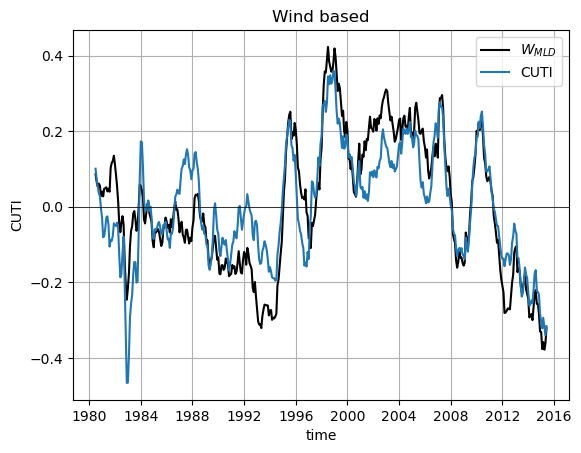

In [161]:
# 13-month smoothed, detrended anomalies (all months)
prep_ia(WMLD_L).plot(label='$W_{MLD}$', color='Black')
prep_ia(CUTI.mean(dim='lat_band')).plot(label='CUTI')
plt.axhline(0, color='k', lw=0.5)
plt.legend()
plt.grid(True)
plt.title('Wind based')

## No Extreme El Niño conditions

* Seasonal cycle removed, linear trend removed, 13-month running mean, then the extreme EN months are masked **after** smoothing (no pad) — `ci_intervals` from `Table2_ci_intervals`.
* $r$, $r^2$ and $p$ use the effective sample size N_eff (autocorrelation-corrected).

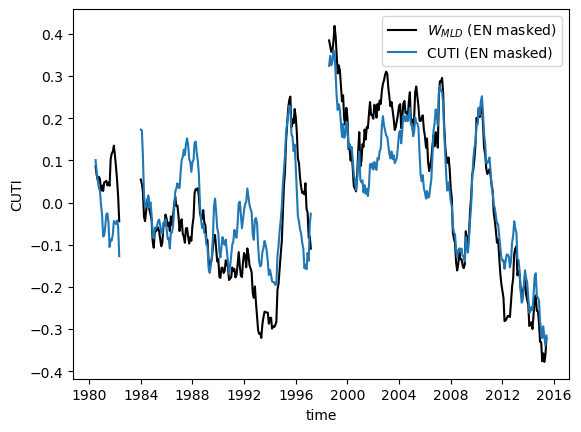

In [162]:
# Interannual series (all months; EN masking is done inside ci_intervals)
wmld_all  = prep_ia(WMLD_L)
CUTI_all  = prep_ia(CUTI.mean(dim='lat_band'))
Uek_all   = prep_ia(hr.U_ek.mean(dim='lat_band'))
BEUTI_all = prep_ia(BEUTI.mean(dim='lat_band'))
CUI_all   = prep_ia(CUI.CUI_cc.mean('lat'))
CHL_all   = prep_ia(CHL.chla.mean(dim=('lat', 'lon')))

# both series masked, as in ci_intervals (r uses only the non-EN months)
wmld_all.where(~_en_mask(wmld_all.time)).plot(label='$W_{MLD}$ (EN masked)', color='k')
CUTI_all.where(~_en_mask(CUTI_all.time)).plot(label='CUTI (EN masked)')
plt.legend()

In [163]:
# Correlation of every index with W_MLD (X = W_MLD, Y = index)
WMLD_ts = WMLD_L
ia_indices = {'CUTI':  CUTI.mean(dim='lat_band'),
              'U_ek':  hr.U_ek.mean(dim='lat_band'),
              'BEUTI': BEUTI.mean(dim='lat_band'),
              'CUI':   CUI.CUI_cc.mean('lat'),
              'Chl-a': CHL.chla.mean(dim=('lat', 'lon'))}
ia_cases = {'EN excluded, no pad': dict(exclude_en=True),
            'all years':           dict(exclude_en=False)}

rows = []
for yname, Y in ia_indices.items():
    for cname, kw in ia_cases.items():
        r = ci_intervals(WMLD_ts, Y, 'W_MLD', yname, pad_months=PAD, **kw)
        r['case'] = cname
        rows.append(r)

cols = ['y', 'case', 'N', 'n_masked', 'tau_x', 'tau_y', 'tau_eff', 'N_eff',
        'rho_hat', 'ci_low', 'ci_high', 'R2', 'p']
ia_table = pd.DataFrame(rows)[cols].round({'tau_eff': 1, 'N_eff': 1, 'rho_hat': 3,
                                           'ci_low': 2, 'ci_high': 2, 'R2': 2})
ia_table['p'] = ia_table['p'].map(lambda v: '< 0.001' if v < 0.001 else f'{v:.3f}')
ia_table

,y,case,N,n_masked,tau_x,tau_y,tau_eff,N_eff,rho_hat,ci_low,ci_high,R2,p
0,CUTI,"EN excluded, no pad",385,35,23,12,15.8,24.4,0.880,0.74,0.95,0.78,< 0.001
1,CUTI,all years,420,0,43,12,18.8,22.4,0.862,0.69,0.94,0.74,< 0.001
2,U_ek,"EN excluded, no pad",385,35,23,11,14.9,25.9,0.856,0.70,0.93,0.73,< 0.001
3,U_ek,all years,420,0,43,12,18.8,22.4,0.711,0.42,0.87,0.51,< 0.001
4,BEUTI,"EN excluded, no pad",385,35,23,12,15.8,24.4,0.848,0.68,0.93,0.72,< 0.001
5,BEUTI,all years,420,0,43,12,18.8,22.4,0.815,0.60,0.92,0.66,< 0.001
6,CUI,"EN excluded, no pad",385,35,23,8,11.9,32.4,-0.060,-0.40,0.29,0.00,0.743
7,CUI,all years,420,0,43,10,16.2,25.9,0.010,-0.38,0.40,0.00,0.962
8,Chl-a,"EN excluded, no pad",385,35,23,9,12.9,29.8,-0.426,-0.68,-0.08,0.18,0.019
9,Chl-a,all years,420,0,43,12,18.8,22.4,-0.353,-0.67,0.08,0.12,0.104


### Scatter plots without EN

In [164]:
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import pearsonr, linregress

lsz = 6

EN1, EN2 = NINO

UNITS = {
    'CUTI':  r'$m^{2} \ s^{-1}$',
    'BEUTI': r'$mmol\,N \ m^{-1} \ s^{-1}$',
    'CUI':   r'$\Delta ^{\circ}C$',
    'Chl':   r'$mg \ m^{-3}$',
}

REF_LABEL = r'$W_{MLD}$ anomaly ($m^{2} \ s^{-1}$)'

# scatter axis labels: 'NAME anomaly (unit)' for interannual anomalies, 'NAME (unit)' for
# seasonal climatologies; names whose label is too long for the axis get the unit on a second line
UNIT_NEWLINE = {'BEUTI', r'CUI / $W_{MLD}$', r'[CUI / $W_{MLD}$]'}
def ax_label(name, unit, anom=True):
    sep = '\n' if name in UNIT_NEWLINE else ' '
    return f"{name}{' anomaly' if anom else ''}{sep}({unit})"
def anom_label(name, unit):
    return ax_label(name, unit, anom=True)

TITLE_LABELS = {
    'CUTI':  'CUTI',
    'BEUTI': 'BEUTI',
    'CUI':   'CUI',
    'Chl':   r'$Chl\text{-}a$',
}

ONE_TO_ONE = ['CUTI']
CUTI_LIM   = (-0.55, 0.55)   # CUTI and W_MLD share units -> same x and y range
CUTI_TICKS = [-0.4, -0.2, 0, 0.2, 0.4]   # same tick labels on both axes

W_MLD vs CUTI (non-EN)       r = +0.880  95% CI = [+0.74, +0.95]  r2 = 0.78  p = 1e-08  N = 385  N_eff = 24.4
W_MLD vs BEUTI (non-EN)      r = +0.848  95% CI = [+0.68, +0.93]  r2 = 0.72  p = 1.3e-07  N = 385  N_eff = 24.4
W_MLD vs CUI (non-EN)        r = -0.060  95% CI = [-0.40, +0.29]  r2 = 0.00  p = 0.74  N = 385  N_eff = 32.4
W_MLD vs Chl (non-EN)        r = -0.426  95% CI = [-0.68, -0.08]  r2 = 0.18  p = 0.019  N = 385  N_eff = 29.8


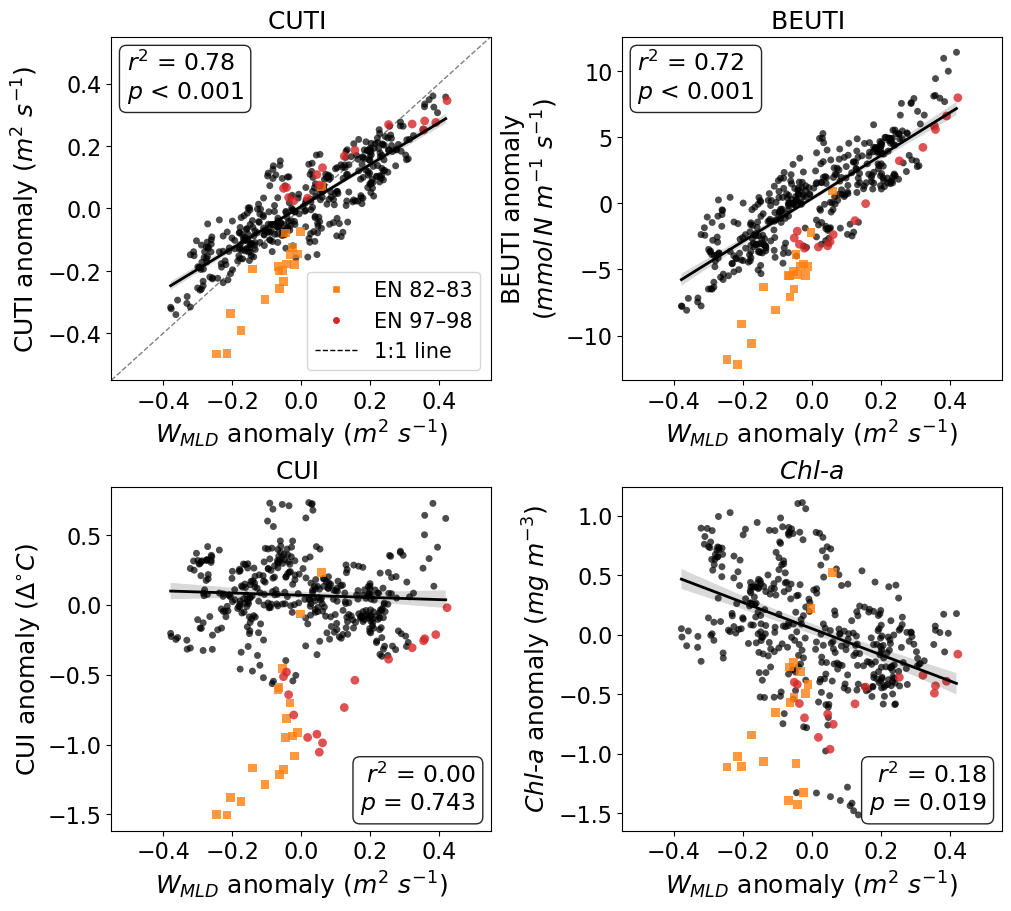

In [165]:
# ============================================================
# 4-panel scatter: CUTI, BEUTI, CUI, Chl-a vs W_MLD (interannual).
# Fit, r^2 and p (N_eff t-test) on non-EN months only (EN masked, no pad).
# ============================================================
all_pairs = {
    'CUTI':  CUTI.mean(dim='lat_band'),
    'BEUTI': BEUTI.mean(dim='lat_band'),
    'CUI':   CUI.CUI_cc.mean('lat'),
    'Chl':   CHL.chla.mean(dim=('lat', 'lon')),
}

fig, axs = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
axs = axs.flatten()

for ax, (name, Y) in zip(axs, all_pairs.items()):
    res, x, y, en1, en2 = ia_pair(WMLD_ts, Y)
    fit = res['valid']

    ax.scatter(x[fit], y[fit], c='black', marker='o',
               edgecolors='none', s=25, alpha=0.7, label='Non-EN')
    ax.scatter(x[en1], y[en1], c='tab:orange', marker='s',
               edgecolors='none', s=40, alpha=0.8, label='EN 1982–83')
    ax.scatter(x[en2], y[en2], c='tab:red', marker='o',
               edgecolors='none', s=40, alpha=0.8, label='EN 1997–98')

    sns.regplot(x=x[fit], y=y[fit], ax=ax, ci=95, scatter=False,
                line_kws={'color': 'black', 'lw': 2})

    if name in ONE_TO_ONE:
        ax.plot(CUTI_LIM, CUTI_LIM, 'k--', lw=1, alpha=0.5, zorder=0)

    # r^2 / p box: upper left, except CUI and Chl-a (lower right)
    if name in ('CUI', 'Chl'):
        tx, ty, va, ha = 0.96, 0.04, 'bottom', 'right'
    else:
        tx, ty, va, ha = 0.04, 0.96, 'top', 'left'
    ax.text(tx, ty, rp_label(res),
            transform=ax.transAxes, va=va, ha=ha, fontsize=11 + lsz,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    title_name = TITLE_LABELS.get(name, name)
    ax.set_xlabel(REF_LABEL, fontsize=12 + lsz)
    ax.set_ylabel(anom_label(title_name, UNITS[name]), fontsize=12 + lsz)
    ax.set_title(f'{title_name} ', fontsize=12 + lsz)
    ax.tick_params(labelsize=10 + lsz)
    # x axis (W_MLD anomaly) identical in all four panels
    ax.set_xlim(CUTI_LIM)
    ax.set_xticks(CUTI_TICKS)
    if name == 'CUTI':               # same units as W_MLD -> same y axis too
        ax.set_ylim(CUTI_LIM)
        ax.set_yticks(CUTI_TICKS)

    print_res(f'W_MLD vs {name} (non-EN)', res)

axs[0].legend(handles=[
    Line2D([0], [0], marker='s', color='w', markerfacecolor='tab:orange', markersize=6, label='EN 82–83'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red', markersize=6, label='EN 97–98'),
    Line2D([0], [0], color='k', linestyle='--', lw=1, label='1:1 line'),
], loc='lower right', frameon=True, fontsize=9 + lsz)

# plt.savefig('Figures/scatter_noEN_indices.pdf', bbox_inches='tight', dpi=300)
plt.show()

U_ek non-EN                  r = +0.856  95% CI = [+0.70, +0.93]  r2 = 0.73  p = 2.7e-08  N = 385  N_eff = 25.9
U_ek all months              r = +0.711  95% CI = [+0.42, +0.87]  r2 = 0.51  p = 0.00018  N = 420  N_eff = 22.4
                             slope non-EN = 0.76, all months = 0.80
CUTI non-EN                  r = +0.880  95% CI = [+0.74, +0.95]  r2 = 0.78  p = 1e-08  N = 385  N_eff = 24.4
CUTI all months              r = +0.862  95% CI = [+0.69, +0.94]  r2 = 0.74  p = 1.9e-07  N = 420  N_eff = 22.4
                             slope non-EN = 0.67, all months = 0.70


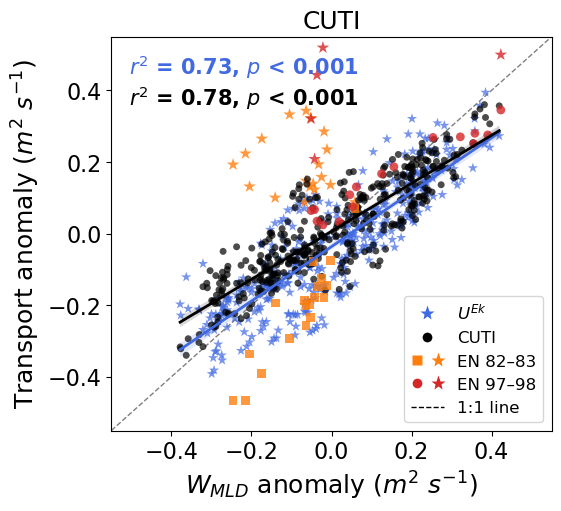

In [166]:
# ============================================================
# CUTI panel only: U^Ek (stars) and CUTI = U^Ek + U^Geo (circles) vs W_MLD.
# EN 82-83 orange (CUTI square / U^Ek star), EN 97-98 red.
# Fits, r^2 and p on non-EN months only (ci_intervals, no pad); slopes printed.
# ============================================================
from matplotlib.legend_handler import HandlerTuple

series = {
    # name: (index, colour, non-EN marker, EN82-83 marker, EN97-98 marker, size)
    'U_ek': (hr.U_ek.mean(dim='lat_band'), 'royalblue', '*', '*', '*', 60),
    'CUTI': (CUTI.mean(dim='lat_band'),    'black',     'o', 's', 'o', 25),
}

fig, ax = plt.subplots(figsize=(5.5, 5), constrained_layout=True)
stats_txt = []

for name, (Y, color, m_non, m_82, m_97, s) in series.items():
    res, x, y, en1, en2 = ia_pair(WMLD_ts, Y)
    fit = res['valid']

    ax.scatter(x[fit], y[fit], c=color, marker=m_non,
               edgecolors='none', s=s, alpha=0.7)
    ax.scatter(x[en1], y[en1], c='tab:orange', marker=m_82,
               edgecolors='none', s=s * 1.5 if m_82 == '*' else 40, alpha=0.8)
    ax.scatter(x[en2], y[en2], c='tab:red', marker=m_97,
               edgecolors='none', s=s * 1.5 if m_97 == '*' else 40, alpha=0.8)

    sns.regplot(x=x[fit], y=y[fit], ax=ax, ci=95, scatter=False,
                line_kws={'color': color, 'lw': 2})

    stats_txt.append((f"$r^2$ = {res['R2']:.2f}, {_ptxt(res['p'])}", color))
    res_all = ci_intervals(WMLD_ts, Y, pad_months=PAD, exclude_en=False)
    print_res(f'{name} non-EN', res)
    print_res(f'{name} all months', res_all)
    print(f"{'':28s} slope non-EN = {linregress(x[fit], y[fit]).slope:.2f}, "
          f"all months = {linregress(x, y).slope:.2f}")

for k, (txt, color) in enumerate(stats_txt):
    ax.text(0.04, 0.96 - 0.08 * k, txt, transform=ax.transAxes, va='top', ha='left',
            color=color, fontsize=9 + lsz, fontweight='bold')

ax.plot(CUTI_LIM, CUTI_LIM, 'k--', lw=1, alpha=0.5, zorder=0)

ax.set_xlabel(REF_LABEL, fontsize=12 + lsz)
ax.set_ylabel(anom_label('Transport', UNITS['CUTI']), fontsize=12 + lsz)
ax.set_title('CUTI', fontsize=12 + lsz)
ax.tick_params(labelsize=10 + lsz)
ax.set_xlim(CUTI_LIM)
ax.set_ylim(CUTI_LIM)

mk = lambda m, c, ms=7: Line2D([0], [0], marker=m, color='w', markerfacecolor=c,
                               markeredgecolor='none', markersize=ms)
handles = [mk('*', 'royalblue', 11),
           mk('o', 'black'),
           (mk('s', 'tab:orange'), mk('*', 'tab:orange', 11)),
           (mk('o', 'tab:red'),    mk('*', 'tab:red', 11)),
           Line2D([0], [0], color='k', linestyle='--', lw=1)]
labels  = [r'$U^{Ek}$', r'CUTI', 'EN 82–83', 'EN 97–98', '1:1 line']
ax.legend(handles, labels, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)},
          loc='lower right', frameon=True, fontsize=9 + lsz - 3)

# with PdfPages('Figures/paper/scatter_CUTI_Uek_v3.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight', dpi=300)

plt.show()

## Now EN

In [167]:
# ============================================================
# Correlation DURING the El Nino events only: same smoothed, detrended
# anomalies (ci_intervals, all months), restricted to the EN months.
# Only ~16-19 consecutive smoothed months per event, i.e. N_eff ~ 1:
# these r values are descriptive, no significance test is possible.
# ============================================================
rows = []
for yname, Y in [('CUTI', ia_indices['CUTI']), ('BEUTI', ia_indices['BEUTI']),
                 ('CUI', ia_indices['CUI']), ('Chl', ia_indices['Chl-a'])]:
    res, x, y, en1, en2 = ia_pair(WMLD_ts, Y, exclude_en=False)
    row = {'name': yname}
    for lab, m in [('EN 82-83', en1), ('EN 97-98', en2), ('both EN', en1 | en2)]:
        row[f'r {lab}'] = np.corrcoef(x[m], y[m])[0, 1]
        row[f'N {lab}'] = int(m.sum())
    rows.append(row)

print('=== W_MLD vs index during El Nino (smoothed, detrended anomalies) ===')
print(pd.DataFrame(rows).set_index('name').round(3))

=== W_MLD vs index during El Nino (smoothed, detrended anomalies) ===
       r EN 82-83  N EN 82-83  r EN 97-98  N EN 97-98  r both EN  N both EN
name                                                                       
CUTI        0.920          19       0.966          16      0.903         35
BEUTI       0.928          19       0.972          16      0.966         35
CUI         0.782          19       0.769          16      0.722         35
Chl         0.548          19       0.594          16      0.427         35


In [168]:
# ============================================================
# How much smaller is the variability of CUTI than that of W_MLD?
# Both are in m^2 s^-1, so their spreads are directly comparable.
# ============================================================
from scipy.stats import pearsonr, linregress

# --- full-length series; interannual = prep_ia (Table2_ci_intervals steps) ---
CUTI_f  = CUTI.mean(dim='lat_band')
WMLD_f  = WMLD_L


def spread(x):
    """std and peak-to-peak of a 1-D series, NaNs ignored."""
    v = np.asarray(x.values, float).ravel()
    v = v[np.isfinite(v)]
    return v.std(ddof=1), v.max() - v.min()


def compare(name, cuti, ref, ref_name):
    s_c, p_c = spread(cuti)
    s_r, p_r = spread(ref)
    print(f'  {name}')
    print(f'     std   CUTI = {s_c:7.4f}   {ref_name} = {s_r:7.4f}   '
          f'ratio = {s_c / s_r:.3f}  ->  CUTI is {100 * (1 - s_c / s_r):5.1f}% smaller')
    print(f'     range CUTI = {p_c:7.4f}   {ref_name} = {p_r:7.4f}   '
          f'ratio = {p_c / p_r:.3f}  ->  CUTI is {100 * (1 - p_c / p_r):5.1f}% smaller')


print('=== 1. Full monthly series (total variability) ===')
compare('monthly', CUTI_f, WMLD_f, 'W_MLD  ')

print('\n=== 2. Seasonal cycle (12-month climatology) ===')
compare('seasonal', seasonality(CUTI_f), seasonality(WMLD_f), 'W_MLD  ')

print('\n=== 3. Interannual (detrended 13-month smoothed anomalies) ===')
cuti_ia  = prep_ia(CUTI_f)
wmld_ia  = prep_ia(WMLD_f)
compare('interannual', cuti_ia, wmld_ia, 'W_MLD  ')

print('\n=== 4. Regression slope of CUTI on the reference (the scatter above) ===')
for ref, nm in [(wmld_ia, 'W_MLD')]:
    a, b = xr.align(cuti_ia, ref, join='inner')
    x = np.asarray(b.values, float).ravel()
    y = np.asarray(a.values, float).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    lr = linregress(x[m], y[m])
    print(f'  CUTI = {lr.slope:.3f} x {nm} + {lr.intercept:+.4f}   '
          f'(r = {lr.rvalue:+.3f}, n = {m.sum()})')
    print(f'     -> CUTI changes only {100 * lr.slope:.0f}% as much per unit {nm}')

print('\n=== 5. NON-EL NINO only (EN masked after smoothing, no pad; as the scatter fit) ===')
cuti_ne  = prep_ia(CUTI_f, exclude_en=True)
wmld_ne  = prep_ia(WMLD_f, exclude_en=True)
compare('interannual, no EN', cuti_ne, wmld_ne,  'W_MLD  ')

for ref, nm in [(wmld_ne, 'W_MLD')]:
    a, b = xr.align(cuti_ne, ref, join='inner')
    x = np.asarray(b.values, float).ravel()
    y = np.asarray(a.values, float).ravel()
    m = np.isfinite(x) & np.isfinite(y)
    lr = linregress(x[m], y[m])
    print(f'  non-EN slope vs {nm}: {lr.slope:.3f}  (r = {lr.rvalue:+.3f}, n = {m.sum()})')


=== 1. Full monthly series (total variability) ===
  monthly
     std   CUTI =  0.5055   W_MLD   =  0.6096   ratio = 0.829  ->  CUTI is  17.1% smaller
     range CUTI =  3.0979   W_MLD   =  3.0087   ratio = 1.030  ->  CUTI is  -3.0% smaller

=== 2. Seasonal cycle (12-month climatology) ===
  seasonal
     std   CUTI =  0.3864   W_MLD   =  0.5247   ratio = 0.736  ->  CUTI is  26.4% smaller
     range CUTI =  1.0561   W_MLD   =  1.4352   ratio = 0.736  ->  CUTI is  26.4% smaller

=== 3. Interannual (detrended 13-month smoothed anomalies) ===
  interannual
     std   CUTI =  0.1477   W_MLD   =  0.1807   ratio = 0.817  ->  CUTI is  18.3% smaller
     range CUTI =  0.8264   W_MLD   =  0.8012   ratio = 1.031  ->  CUTI is  -3.1% smaller

=== 4. Regression slope of CUTI on the reference (the scatter above) ===
  CUTI = 0.705 x W_MLD + +0.0007   (r = +0.862, n = 420)
     -> CUTI changes only 70% as much per unit W_MLD

=== 5. NON-EL NINO only (EN masked after smoothing, no pad; as the scatter 

In [169]:
# ============================================================
# Variation relative to the climatological mean, NON-EL NINO months only.
# Normalising by each index's own mean makes BEUTI (mmol N m-1 s-1)
# comparable with CUTI and W_MLD (m2 s-1).
# ============================================================
BEUTI_f = BEUTI.mean(dim='lat_band')

indices = {'W_MLD': WMLD_f, 'CUTI': CUTI_f, 'BEUTI': BEUTI_f}

print(f"{'index':7s} {'regime':10s} {'mean':>9s} {'range':>9s} "
      f"{'range/mean':>11s} {'std/mean':>9s}")
for name, da in indices.items():
    for regime, series in [('all years', da), ('non-EN', drop_en_events(da))]:
        clim = seasonality(series)
        mean = float(clim.mean('month'))
        rng  = float(clim.max() - clim.min())
        sd   = float(np.nanstd(np.asarray(series.values, float).ravel(), ddof=1))
        print(f'{name:7s} {regime:10s} {mean:9.4f} {rng:9.4f} '
              f'{100 * rng / mean:10.1f}% {100 * sd / mean:8.1f}%')

print('\nrange/mean = (max month - min month) / annual mean  '
      '<- same metric as the 91.6% quoted for W_MLD')
print('std/mean   = coefficient of variation of the monthly series')


index   regime          mean     range  range/mean  std/mean
W_MLD   all years     1.5347    1.4352       93.5%     39.7%
W_MLD   non-EN        1.5433    1.4685       95.2%     39.9%
CUTI    all years     1.7781    1.0561       59.4%     28.4%
CUTI    non-EN        1.7861    1.0561       59.1%     26.8%
BEUTI   all years    36.3375   33.2130       91.4%     40.9%
BEUTI   non-EN       36.8299   33.4991       91.0%     39.5%

range/mean = (max month - min month) / annual mean  <- same metric as the 91.6% quoted for W_MLD
std/mean   = coefficient of variation of the monthly series


In [170]:
# ============================================================
# Interannual variability under NON-EL NINO conditions, as a percentage of
# each index's own climatological mean (a coefficient of variation).
#
#                 std( detrended 13-month smoothed anomalies, EN masked )
#   rel. var. =  ----------------------------------------------- x 100
#                 mean( raw series, EN removed )   <- climatological mean
#
# The denominator CANNOT be the mean of the anomalies: subtracting the
# climatology sets that to ~0 by construction (verified in the last column).
# ============================================================
print(f"{'index':7s} {'clim mean':>10s} {'IA std':>9s} {'IA std/mean':>12s} "
      f"{'vs W_MLD':>9s} {'mean(anom)':>12s}")
ref = None
for name, da in [('W_MLD', WMLD_f), ('BEUTI', BEUTI_f), ('CUTI', CUTI_f)]:
    mean_raw  = float(drop_en_events(da).mean())        # climatological mean
    ia        = prep_ia(da, exclude_en=True)            # smoothed anomalies
    sd        = float(np.nanstd(np.asarray(ia.values, float).ravel(), ddof=1))
    mean_anom = float(np.nanmean(np.asarray(ia.values, float).ravel()))
    rel = 100 * sd / mean_raw
    if ref is None:
        ref = rel
    print(f'{name:7s} {mean_raw:10.4f} {sd:9.4f} {rel:11.1f}% '
          f'{100 * rel / ref:8.0f}% {mean_anom:12.2e}')

print('\nLast column = mean of the anomalies. It is ~0, which is why it cannot')
print('be the denominator. Compare what you would get if it were:')
for name, da in [('W_MLD', WMLD_f), ('BEUTI', BEUTI_f), ('CUTI', CUTI_f)]:
    ia = prep_ia(da, exclude_en=True)
    v  = np.asarray(ia.values, float).ravel()
    print(f'  {name:7s} std/mean(anom) = {100 * np.nanstd(v, ddof=1) / np.nanmean(v):+12.1f}%'
          '   <- unstable / meaningless')


index    clim mean    IA std  IA std/mean  vs W_MLD   mean(anom)
W_MLD       1.5352    0.1814        11.8%      100%     2.10e-03
BEUTI      36.6303    3.4707         9.5%       80%     4.04e-01
CUTI        1.7800    0.1382         7.8%       66%     7.74e-03

Last column = mean of the anomalies. It is ~0, which is why it cannot
be the denominator. Compare what you would get if it were:
  W_MLD   std/mean(anom) =      +8623.2%   <- unstable / meaningless
  BEUTI   std/mean(anom) =       +859.5%   <- unstable / meaningless
  CUTI    std/mean(anom) =      +1786.4%   <- unstable / meaningless


In [171]:
# ============================================================
# Numbers for the paragraph "CUTI reproduces only X% of the interannual std of
# W_MLD ... CV ... r2 for U^Ek alone and CUTI ... RMSE reduced by Y%".
# Non-EN months only, v3 pipeline (detrended 13-month smoothed anomalies,
# EN masked, ci_intervals with no pad).
#   std ratio      = std(CUTI anom) / std(W_MLD anom)
#   CV             = std(anom) / climatological mean (raw series, EN removed)
#   RMSE           = sqrt(mean((index - W_MLD)^2)) on the anomalies, m2/s
#   RMSE reduction = (RMSE_Uek - RMSE_CUTI) / RMSE_Uek
# ============================================================
sd = {}
for name, da in [('W_MLD', WMLD_f), ('BEUTI', BEUTI_f), ('CUTI', CUTI_f)]:
    ia = prep_ia(da, exclude_en=True)
    sd[name] = float(np.nanstd(np.asarray(ia.values, float).ravel(), ddof=1))
    cv = 100 * sd[name] / float(drop_en_events(da).mean())
    print(f'{name:6s} IA std = {sd[name]:.4f}   CV = {cv:.1f}%')
print(f'\nstd(CUTI) / std(W_MLD) = {100 * sd["CUTI"] / sd["W_MLD"]:.0f}%\n')

rmse = {}
for name, Y in [('U_ek', hr.U_ek.mean(dim='lat_band')), ('CUTI', CUTI.mean(dim='lat_band'))]:
    res, x, y, en1, en2 = ia_pair(WMLD_ts, Y)
    fit = res['valid']
    rmse[name] = float(np.sqrt(np.mean((y[fit] - x[fit]) ** 2)))
    print(f"{name:5s} r2 = {res['R2']:.2f}   RMSE = {rmse[name]:.3f} m2/s   N = {fit.sum()}")
print(f'-> CUTI reduces the RMSE by {100 * (rmse["U_ek"] - rmse["CUTI"]) / rmse["U_ek"]:.0f}% relative to U_ek')


W_MLD  IA std = 0.1814   CV = 11.8%
BEUTI  IA std = 3.4707   CV = 9.5%
CUTI   IA std = 0.1382   CV = 7.8%

std(CUTI) / std(W_MLD) = 76%

U_ek  r2 = 0.73   RMSE = 0.101 m2/s   N = 385
CUTI  r2 = 0.78   RMSE = 0.089 m2/s   N = 385
-> CUTI reduces the RMSE by 12% relative to U_ek


In [172]:
# ============================================================
# How much does W_MLD weaken / strengthen during each El Nino?
#
# The two events span different calendar months, so raw means are confounded
# by the seasonal cycle. We therefore remove the climatology first and express
# the event-mean anomaly as a percentage of the climatological mean.
# ============================================================
EVENTS = {'EN 1982-83': NINO[0], 'EN 1997-98': NINO[1]}

CHL_f = CHL.chla.mean(dim=('lat', 'lon'))
CUI_f = CUI.CUI_cc.mean('lat')

for label, da in [('W_MLD', WMLD_f), ('CUTI', CUTI_f), ('BEUTI', BEUTI_f),
                  ('Chl-a', CHL_f), ('CUI', CUI_f)]:
    clim   = da.groupby('time.month').mean('time')
    anom   = da.groupby('time.month') - clim          # unsmoothed anomaly
    base   = float(drop_en_events(da).mean())         # climatological mean
    print(f'{label}   (climatological mean = {base:.4f})')
    for name, (t0, t1) in EVENTS.items():
        sel = anom.sel(time=slice(t0, t1))
        a   = float(sel.mean())
        pct = 100 * a / base
        verb = 'weakens ' if pct < 0 else 'strengthens'
        print(f'    {name}:  mean anomaly = {a:+.4f}   ->  {verb} {abs(pct):.0f}%'
              f'   (n = {sel.sizes["time"]} months)')
    print()

# raw (not seasonally adjusted) comparison, for reference only
print('--- raw event mean vs climatological mean (confounded by season) ---')
for name, (t0, t1) in EVENTS.items():
    ev   = float(WMLD_f.sel(time=slice(t0, t1)).mean())
    base = float(drop_en_events(WMLD_f).mean())
    print(f'  W_MLD {name}: {ev:.4f} vs {base:.4f}  ->  {100 * (ev - base) / base:+.0f}%')

# CUI is a temperature difference: its climatological mean can sit near zero,
# which makes a "% of mean" unstable. Check the denominator before quoting it.
print(f'\nCUI climatological mean = {float(drop_en_events(CUI_f).mean()):.4f} degC'
      '   <- if small, quote CUI in degC, not %')

W_MLD   (climatological mean = 1.5352)
    EN 1982-83:  mean anomaly = -0.2772   ->  weakens  18%   (n = 19 months)
    EN 1997-98:  mean anomaly = +0.1183   ->  strengthens 8%   (n = 16 months)

CUTI   (climatological mean = 1.7800)
    EN 1982-83:  mean anomaly = -0.3317   ->  weakens  19%   (n = 19 months)
    EN 1997-98:  mean anomaly = +0.1962   ->  strengthens 11%   (n = 16 months)

BEUTI   (climatological mean = 36.6303)
    EN 1982-83:  mean anomaly = -10.1011   ->  weakens  28%   (n = 19 months)
    EN 1997-98:  mean anomaly = -0.1564   ->  weakens  0%   (n = 16 months)

Chl-a   (climatological mean = 5.4773)
    EN 1982-83:  mean anomaly = -0.4510   ->  weakens  8%   (n = 19 months)
    EN 1997-98:  mean anomaly = -0.6000   ->  weakens  11%   (n = 16 months)

CUI   (climatological mean = 3.1391)
    EN 1982-83:  mean anomaly = -0.9206   ->  weakens  29%   (n = 19 months)
    EN 1997-98:  mean anomaly = -0.6674   ->  weakens  21%   (n = 16 months)

--- raw event mean vs climat

## Amplitude of drivers

In [173]:
SST = xr.open_dataset('../data/SST.nc').compute()
SST= SST.where(SST.SST!=0,np.nan)


mask = coastal_band_mask(SST,'SST',mask_km).sel(lon=slice(-85,None),lat=slice(-16,-5))
SST = SST.where(mask).SST

SSTs   = prep_ia(SST.mean(dim=('lat','lon')))
# SSTs

In [174]:
SSH = xr.open_dataset('../data/SSH.nc').compute()
SSH= SSH.where(SSH.SSH!=0,np.nan)
SSH = SSH.where(mask).SSH

SSHs   = prep_ia(SSH.mean(dim=('lat','lon')))
# SSHs

In [175]:
MLD = xr.open_dataset('../data/MLD.nc').compute()
MLD = MLD.where(mask).MLD
MLDs   = prep_ia(MLD.mean(dim=('lat','lon')))
MLDs

<xarray.DataArray 'MLD' (time: 420)> Size: 3kB
array([-1.43591235e-01, -2.89278134e-01, -4.55536243e-01, -2.52540883e-01,
       -3.00042696e-01,  1.11456714e-01,  1.02686718e+00,  1.95839227e+00,
        2.62927794e+00,  1.88155135e+00,  1.14481159e+00,  7.12599219e-01,
        1.03930044e+00,  1.71012336e+00,  3.23588787e+00,  4.10778823e+00,
        4.36267998e+00,  4.76498690e+00,  4.78133512e+00,  4.67908465e+00,
        3.89669306e+00,  3.06445891e+00,  3.43798177e+00,  4.41042303e+00,
        5.76891672e+00,  6.27839061e+00,  5.62192258e+00,  4.74749562e+00,
        5.02484205e+00,  6.03921545e+00,  6.07845684e+00,  5.45364581e+00,
        5.23978187e+00,  5.30270586e+00,  5.48131814e+00,  5.00853437e+00,
        3.97201583e+00,  2.70904631e+00,  1.97159702e+00,  1.67458212e+00,
        1.24297170e+00,  4.50194976e-01, -8.55916104e-01, -4.95410841e-01,
        4.33579492e-01,  2.84715643e-01,  1.63456396e-01,  2.74674496e-01,
        5.48164941e-01,  5.84231310e-01,  1.15633407e-01, -1.60878339e-01,
       -1.36003374e-01, -5.87652625e-01, -8.94492772e-01, -8.34366772e-01,
       -1.45796772e+00, -2.62980090e+00, -3.10459864e+00, -3.30662498e+00,
       -3.52164466e+00, -3.73695291e+00, -3.43385415e+00, -2.74445898e+00,
       -2.49185335e+00, -2.09092417e+00, -1.34519392e+00, -9.69622588e-01,
       -7.97729764e-01, -8.19147306e-01, -4.55243405e-01, -7.93379813e-01,
       -4.76968802e-01, -2.09534912e-01,  1.37650671e-01, -6.46168716e-02,
       -3.51787963e-02, -1.33557286e-01, -1.09248109e+00, -2.20460587e+00,
...
       -2.42126896e+00, -2.72364412e+00, -2.69372868e+00, -2.69460076e+00,
       -1.86105207e+00, -1.69143722e+00, -2.37837748e+00, -2.03407096e+00,
       -1.09982326e+00, -5.81332564e-01, -1.14202800e-01, -7.59402217e-02,
        4.02541104e-01,  1.12078270e+00,  2.38310813e+00,  2.60701326e+00,
        2.96163764e+00,  2.92705121e+00,  2.91988810e+00,  3.11940829e+00,
        2.71765043e+00,  1.89583921e+00,  1.66977507e+00,  1.38486202e+00,
        1.51903581e+00,  1.32820533e+00,  1.18544097e+00,  7.98695471e-01,
        5.89620282e-01,  5.36565458e-01, -2.06841067e-01, -6.47003678e-01,
       -9.63375507e-01, -1.22243270e+00, -1.16954834e+00, -1.62729648e+00,
       -1.87120913e+00, -2.69068884e+00, -2.82285644e+00, -3.03539287e+00,
       -3.97931877e+00, -4.45999099e+00, -4.60043437e+00, -4.41499683e+00,
       -4.31134050e+00, -4.19900625e+00, -3.67158510e+00, -3.08468119e+00,
       -2.81945324e+00, -2.37758622e+00, -1.76413656e+00, -1.54119671e+00,
       -2.11049033e+00, -1.48888777e+00, -1.17445869e+00, -1.49157790e+00,
       -1.60015747e+00, -1.19758927e+00, -9.70275090e-01, -9.39408820e-01,
       -1.54514474e+00, -1.53992232e+00, -1.19810383e+00, -1.43740455e+00,
       -1.37119567e+00, -1.34923741e+00, -1.67801181e+00, -1.29259324e+00,
       -7.83017638e-01, -6.33019649e-01, -9.95610180e-01, -1.04190461e+00,
       -1.40257996e+00, -1.76113680e+00, -1.20747845e+00, -1.45673141e+00,
       -1.59882014e+00, -1.40139873e+00,  4.49029222e-03,  1.16228706e+00])
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-07-01 1980-08-01 ... 2015-06-01

In [176]:
wmld_EN  = prep_ia(WMLD_L)
CUTI_EN  = prep_ia(CUTI.mean(dim=('lat_band')))
BEUTI_EN = prep_ia(BEUTI.mean(dim=('lat_band')))
CUI_EN   = prep_ia(CUI.CUI_cc.mean('lat'))
CHL_EN   = prep_ia(CHL.chla.mean(dim=('lat', 'lon')))


In [177]:
def anomaly(da, dim='time'):
    """Climatology removal → running mean → drop NaNs"""
    clim = da.groupby(f'{dim}.month').mean(dim=dim)
    anom = da.groupby(f'{dim}.month') - clim
    
    return anom

def drop_en_events(da, en_windows=NINO, dim='time'):
    """Mask out El Niño periods from a time series."""
    mask = np.ones(da.sizes[dim], dtype=bool)
    time = da[dim].values
    for start, end in en_windows:
        start64 = np.datetime64(start)
        end64   = np.datetime64(end)
        mask &= ~((time >= start64) & (time <= end64))
    return da.isel({dim: mask})

MLD_all = drop_en_events(MLD*-1)

W = xr.open_dataset('../data/W_depth.nc').compute()
MLD = xr.open_dataset('../data/MLD.nc').compute()
MLD = MLD.where(mask).sel(lon=slice(-85,None),lat=slice(-16,-5))

W_EN_8384 = anomaly(W.w*86400).sel(depth=slice(0,-300)).sel(time=slice("1982-06","1983-12"))
W_EN_9798 = anomaly(W.w*86400).sel(depth=slice(0,-300)).sel(time=slice("1997-04","1998-07"))


MLD_EN_8384 = (MLD*-1).sel(time=slice("1982-06","1983-12"))
MLD_EN_9798 = (MLD*-1).sel(time=slice("1997-04","1998-07"))

MLD_all = drop_en_events(MLD*-1)

In [178]:
w_mean_EN_8384 = W_EN_8384.mean(dim='time')
w_std_EN_8384  = W_EN_8384.std(dim='time')
depth_8384     = W_EN_8384['depth']
mld_en_82      = float(MLD_EN_8384.MLD.mean())
mld_all_val    = float(MLD_all.MLD.mean())

In [179]:
# ============================================================
# Vertical W profile: weakening / strengthening during each El Nino,
# as a percentage of the climatological mean (panels d and e).
#
# Depth-integrated over the upper 200 m: the ratio is taken between the
# depth-MEAN anomaly and the depth-MEAN climatology, NOT as the mean of
# per-depth ratios, because W approaches zero at some depths and the
# per-depth percentages blow up there.
# ============================================================
W_day = W.w * 86400                                   # m/day
W_clim_prof = drop_en_events(W_day).mean('time')      # climatological profile

TOP = -200          # integrate over 0 .. -200 m
sl  = dict(depth=slice(0, TOP))

for name, (t0, t1) in [('EN 1982-83', ('1982-06', '1983-12')),
                       ('EN 1997-98', ('1997-04', '1998-07'))]:
    anom_prof = anomaly(W_day).sel(time=slice(t0, t1)).mean('time')
    a = float(anom_prof.sel(**sl).mean())             # depth-mean anomaly
    c = float(W_clim_prof.sel(**sl).mean())           # depth-mean climatology
    pct = 100 * a / c
    verb = 'weakening' if pct < 0 else 'strengthening'
    print(f'{name}  (0 to {TOP} m)')
    print(f'    depth-mean climatology = {c:+.4f} m/day')
    print(f'    depth-mean anomaly     = {a:+.4f} m/day')
    print(f'    -> general {verb} of {abs(pct):.0f}%')

    # is the change uniform with depth, or driven by one layer?
    r = (anom_prof.sel(**sl) / W_clim_prof.sel(**sl)) * 100
    print(f'    per-depth % ranges {float(r.min()):+.0f}% to {float(r.max()):+.0f}%'
          f'  (spread indicates how uniform the change is)\n')


EN 1982-83  (0 to -200 m)
    depth-mean climatology = +0.6089 m/day
    depth-mean anomaly     = -0.1748 m/day
    -> general weakening of 29%
    per-depth % ranges -2637% to +181%  (spread indicates how uniform the change is)

EN 1997-98  (0 to -200 m)
    depth-mean climatology = +0.6089 m/day
    depth-mean anomaly     = -0.0369 m/day
    -> general weakening of 6%
    per-depth % ranges -217% to +10%  (spread indicates how uniform the change is)



In [180]:
# ============================================================
# Mixed-layer deepening during each El Nino, as a % of the climatological mean.
# MLD is stored as a POSITIVE depth, so a positive anomaly = deeper.
# ============================================================
mld_ts   = MLD.MLD.mean(dim=('lat', 'lon'))          # positive depth, m
base_mld = float(drop_en_events(mld_ts).mean())      # climatological mean

clim_m   = mld_ts.groupby('time.month').mean('time')
anom_mld = mld_ts.groupby('time.month') - clim_m

print(f'MLD climatological mean = {base_mld:.2f} m\n')
for name, (t0, t1) in [('EN 1982-83', ('1982-06', '1983-12')),
                       ('EN 1997-98', ('1997-04', '1998-07'))]:
    a   = float(anom_mld.sel(time=slice(t0, t1)).mean())     # deseasonalised
    raw = float(mld_ts.sel(time=slice(t0, t1)).mean())       # raw event mean
    verb = 'deepens' if a > 0 else 'shoals '
    print(f'{name}')
    print(f'    deseasonalised: anomaly {a:+.2f} m  ->  {verb} {abs(100 * a / base_mld):.0f}%')
    print(f'    raw           : {raw:.2f} m vs {base_mld:.2f} m'
          f'  ->  {100 * (raw - base_mld) / base_mld:+.0f}%')


MLD climatological mean = 28.34 m

EN 1982-83
    deseasonalised: anomaly +3.90 m  ->  deepens 14%
    raw           : 35.88 m vs 28.34 m  ->  +27%
EN 1997-98
    deseasonalised: anomaly +1.63 m  ->  deepens 6%
    raw           : 31.62 m vs 28.34 m  ->  +12%


## CUTI components in time

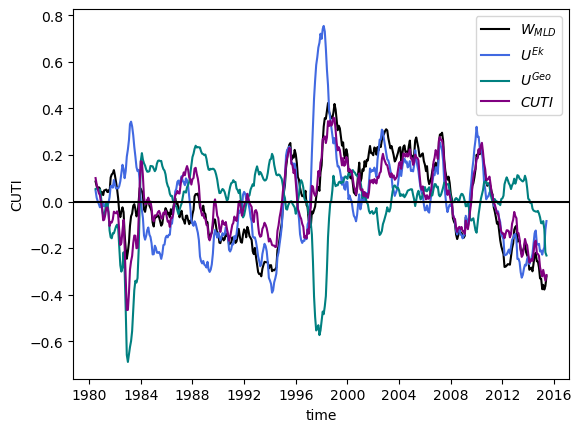

In [181]:
# order: W_MLD, U_ek, U_geo, CUTI (same colours as the zoom panels of the combined plot)
# 13-month smoothed, detrended anomalies
prep_ia(WMLD_L).plot(label='$W_{MLD}$', color='black')
prep_ia(hr.U_ek.mean('lat_band')).plot(label='$U^{Ek}$', color='royalblue')
prep_ia(hr.UGEO.mean('lat_band')).plot(label='$U^{Geo}$', color='teal')
prep_ia(hr.CUTI.mean('lat_band')).plot(label='$CUTI$', color='purple')
plt.axhline(y=0,color='k')
plt.legend()

## Combined plot

In [182]:
import matplotlib.gridspec as gridspec

# Panel (a): full record, detrended 13-month smoothed anomalies (prep_ia)
wmld_all  = prep_ia(WMLD_L)
CUTI_all  = prep_ia(CUTI.mean(dim='lat_band'))
BEUTI_all = prep_ia(BEUTI.mean(dim='lat_band'))
CUI_all   = prep_ia(CUI.CUI_cc.mean('lat'))
CHL_all   = prep_ia(CHL.chla.mean(dim=('lat', 'lon')))

lw = 2

def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

rectangles = [
    (datetime.datetime(1982, 6, 1),  datetime.datetime(1983, 12, 31)),
    (datetime.datetime(1997, 4, 1),  datetime.datetime(1998, 7, 31)),
]

def add_en_shading(ax, ylims):
    for start, end in rectangles:
        rect = Rectangle(
            (mdates.date2num(start), ylims[0]),
            mdates.date2num(end) - mdates.date2num(start),
            ylims[1] - ylims[0],
            facecolor='firebrick', edgecolor='firebrick',
            alpha=0.15, zorder=0,
        )
        ax.add_patch(rect)


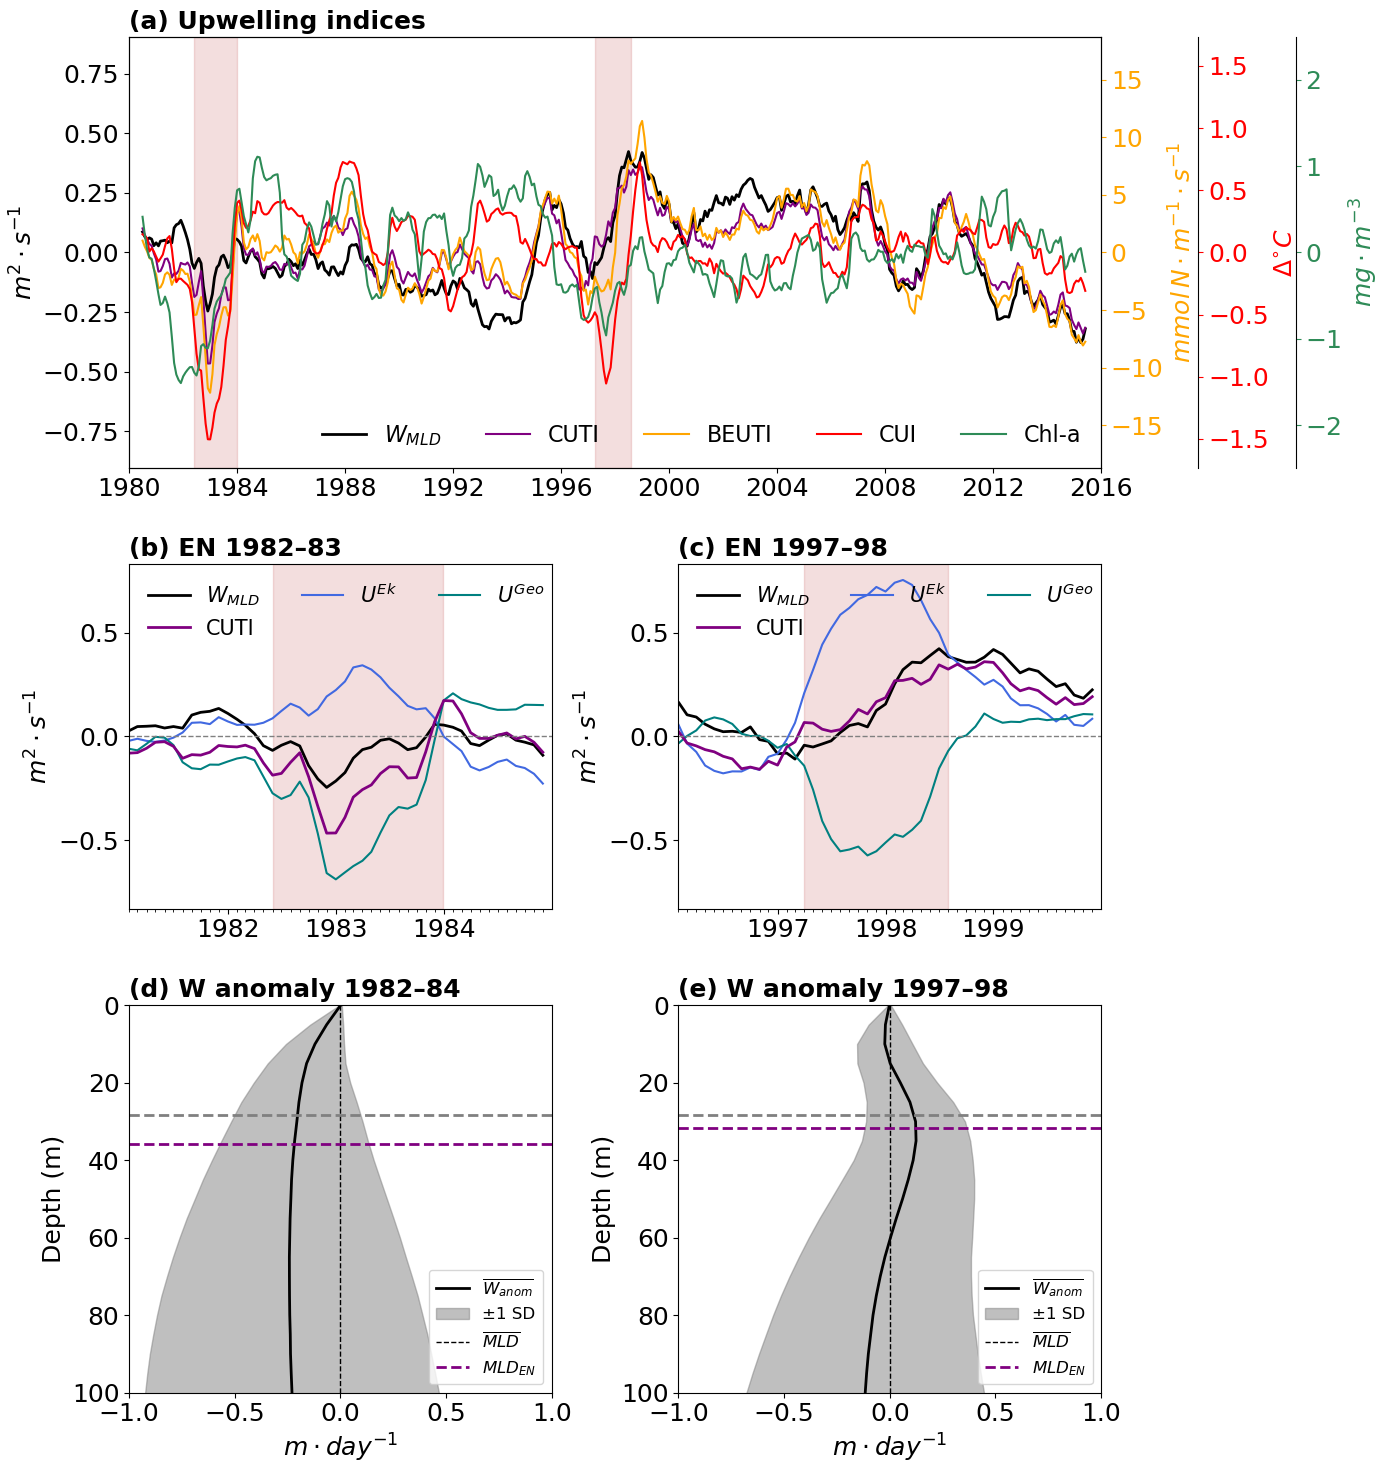

In [183]:
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle

# Same combined figure, but panels (d) and (e) on a LINEAR depth axis, 0-100 m
DEPTH_TICKS = [0, -20, -40, -60, -80, -100]

# Panel (a): full record, detrended 13-month smoothed anomalies (prep_ia)
wmld_all  = prep_ia(WMLD_L)
CUTI_all  = prep_ia(CUTI.mean(dim='lat_band'))
BEUTI_all = prep_ia(BEUTI.mean(dim='lat_band'))
CUI_all   = prep_ia(CUI.CUI_cc.mean('lat'))
CHL_all   = prep_ia(CHL.chla.mean(dim=('lat', 'lon')))

lw = 2

def make_patch_spines_invisible(ax):
    ax.set_frame_on(True)
    ax.patch.set_visible(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

rectangles = [
    (datetime.datetime(1982, 6, 1),  datetime.datetime(1983, 12, 31)),
    (datetime.datetime(1997, 4, 1),  datetime.datetime(1998, 7, 31)),
]

def add_en_shading(ax, ylims):
    for start, end in rectangles:
        rect = Rectangle(
            (mdates.date2num(start), ylims[0]),
            mdates.date2num(end) - mdates.date2num(start),
            ylims[1] - ylims[0],
            facecolor='firebrick', edgecolor='firebrick',
            alpha=0.15, zorder=0,
        )
        ax.add_patch(rect)

# ============================================================
# Figure layout: 1 full-width combined row + 2 pairs of half-width below
# ============================================================
fig = plt.figure(figsize=(18*0.8, 22*0.8))   # original paper size
gs = gridspec.GridSpec(3, 2,
                       height_ratios=[1, 0.8, 0.9],
                       hspace=0.25, wspace=0.3)   # zoom panels no longer carry 3 extra right axes

ax_main = fig.add_subplot(gs[0, :])   # (a) full-width combined indices
ax_en82 = fig.add_subplot(gs[1, 0])   # (b) EN 82-83 time series
ax_en97 = fig.add_subplot(gs[1, 1])   # (c) EN 97-98 time series
ax_w82  = fig.add_subplot(gs[2, 0])   # (d) W profile 82-84
ax_w97  = fig.add_subplot(gs[2, 1])   # (e) W profile 97-98

# ============================================================
# (a) Combined panel — WMLD + CUTI (host) and BEUTI, CUI, Chl (twin axes)
# ============================================================
par1 = ax_main.twinx()   # BEUTI
par2 = ax_main.twinx()   # CUI
par3 = ax_main.twinx()   # Chl

par2.spines["right"].set_position(("axes", 1.10))
par3.spines["right"].set_position(("axes", 1.20))
make_patch_spines_invisible(par2)
make_patch_spines_invisible(par3)
par2.spines["right"].set_visible(True)
par3.spines["right"].set_visible(True)

# Host: WMLD + CUTI (share m^2/s)
p_w,  = ax_main.plot(wmld_all.time, wmld_all, lw=2,   color='black',  label=r'$W_{MLD}$')
p_cu, = ax_main.plot(CUTI_all.time, CUTI_all, lw=1.5, color='purple', label='CUTI')

# Twin axes
p_b,  = par1.plot(BEUTI_all.time, BEUTI_all, lw=1.5, color='orange',   label='BEUTI')
p_c,  = par2.plot(CUI_all.time,   CUI_all,   lw=1.5, color='red',      label='CUI')
p_ch, = par3.plot(CHL_all.time,   CHL_all,   lw=1.5, color='seagreen', label='Chl-a')

ax_main.set_ylabel(r'$m^{2} \cdot s^{-1}$', fontsize=16 + lw)
par1.set_ylabel(r'$mmol\,N \cdot m^{-1} \cdot s^{-1}$', fontsize=16 + lw)
par2.set_ylabel(r'$\Delta ^{\circ}C$', fontsize=16 + lw)
par3.set_ylabel(r'$mg \cdot m^{-3}$', fontsize=16 + lw)

ax_main.yaxis.label.set_color('black')
par1.yaxis.label.set_color('orange')
par2.yaxis.label.set_color('red')
par3.yaxis.label.set_color('seagreen')

ax_main.tick_params(axis='y', colors='black',    labelsize=16 + lw)
par1.tick_params(axis='y',    colors='orange',   labelsize=16 + lw)
par2.tick_params(axis='y',    colors='red',      labelsize=16 + lw)
par3.tick_params(axis='y',    colors='seagreen', labelsize=16 + lw)

k = 5
ax_main.set_ylim(-k * wmld_all.std().item(),  k * wmld_all.std().item())
par1.set_ylim(-k * BEUTI_all.std().item(),    k * BEUTI_all.std().item())
par2.set_ylim(-k * CUI_all.std().item(),      k * CUI_all.std().item())
par3.set_ylim(-k * CHL_all.std().item(),      k * CHL_all.std().item())

# ax_main.grid(True, linewidth=0.1, color='lightgrey')
ax_main.set_axisbelow(True)
ax_main.tick_params(axis='x', which='major', labelsize=16 + lw)
ax_main.set_title('(a) Upwelling indices', fontsize=16 + lw, loc='left', fontweight='bold')
ax_main.set_xlim(datetime.datetime(1980, 1, 1), datetime.datetime(2016, 1, 1))
add_en_shading(ax_main, ax_main.get_ylim())

handles = [p_w, p_cu, p_b, p_c, p_ch]
labels  = [h.get_label() for h in handles]
ax_main.legend(handles, labels, fontsize=14 + lw, ncol=5, frameon=False, loc='lower right')

# ============================================================
# Helper for EN zoom panels: W_MLD and CUTI components, as in the cell above
# (anomaly, detrended, 5S-16S mean, 13-month centred running mean)
# ============================================================
comp_an = {k: prep_ia(v.mean('lat_band'))
           for k, v in [('U_ek', hr.U_ek), ('UGEO', hr.UGEO), ('CUTI', hr.CUTI)]}
# W_MLD as in panel (a): band-mean W x 111 km
comp_an['WMLD'] = prep_ia(WMLD_L)
comp_style = [('WMLD', 'black',     r'$W_{MLD}$'),
              ('U_ek', 'royalblue', r'$U^{Ek}$'),
              ('UGEO', 'teal',      r'$U^{Geo}$'),
              ('CUTI', 'purple',    'CUTI')]

windows = {'82': ("1981-01-01", "1984-12-31"), '97': ("1996-01-01", "1999-12-31")}
# same symmetric y-limits for both zoom panels
ymax = 1.1 * max(float(abs(comp_an[k].sel(time=slice(*w))).max())
                 for k in comp_an for w in windows.values())


def plot_en_panel(ax, title, xlim, window, keep_left=True):
    for key, color, label in comp_style:
        da = comp_an[key].sel(time=slice(*window))
        ax.plot(da.time, da, lw=2 if key in ('CUTI', 'WMLD') else 1.5, color=color, label=label)
    ax.axhline(0, color='gray', linestyle='--', lw=1)

    ax.set_ylim(-ymax, ymax)
    ax.set_ylabel(r'$m^{2} \cdot s^{-1}$', fontsize=16 + lw)
    ax.tick_params(axis='both', labelsize=16 + lw)

    ax.set_xlim(*xlim)
    ax.xaxis.set_major_locator(mdates.YearLocator(base=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())

    add_en_shading(ax, ax.get_ylim())
    ax.set_axisbelow(True)
    ax.set_title(title, fontsize=16 + lw, loc='left', fontweight='bold')
    # matplotlib fills legend columns first; reorder so it reads row by row:
    # W_MLD, U_ek / U_geo, CUTI
    ncol = 3
    h, l = ax.get_legend_handles_labels()
    nrow = -(-len(h) // ncol)
    order = [i * ncol + j for j in range(ncol) for i in range(nrow) if i * ncol + j < len(h)]
    ax.legend([h[k] for k in order], [l[k] for k in order],
              fontsize=15, frameon=False, loc='upper left', ncol=ncol)

# ============================================================
# (b) EN 1982-83: CUTI components
# ============================================================
plot_en_panel(
    ax_en82, '(b) EN 1982–83',
    (datetime.datetime(1981, 2, 1), datetime.datetime(1984, 12, 31)),
    windows['82'], keep_left=True,
)

# ============================================================
# (c) EN 1997-98: CUTI components
# ============================================================
plot_en_panel(
    ax_en97, '(c) EN 1997–98',
    (datetime.datetime(1996, 2, 1), datetime.datetime(1999, 12, 31)),
    windows['97'], keep_left=False,
)

# ============================================================
# (d) W vertical profile - EN 1982-84 (bottom left)
# ============================================================
w_mean_EN_8384 = W_EN_8384.mean(dim='time')
w_std_EN_8384  = W_EN_8384.std(dim='time')
depth_8384     = W_EN_8384['depth']
mld_en_82      = float(MLD_EN_8384.MLD.mean())
mld_all_val    = float(MLD_all.MLD.mean())

ax_w82.plot(w_mean_EN_8384, depth_8384, color='black', lw=2)
ax_w82.fill_betweenx(depth_8384,
                     w_mean_EN_8384 - w_std_EN_8384,
                     w_mean_EN_8384 + w_std_EN_8384,
                     color='gray', alpha=0.5)
ax_w82.axvline(0, color='black', linestyle='--', lw=1)
ax_w82.axhline(mld_en_82,   color='purple', linestyle='--', lw=2)
ax_w82.axhline(mld_all_val, color='gray',   linestyle='--', lw=2)

# linear depth axis, 0-100 m
ax_w82.set_ylim([-100, 0])
ax_w82.set_xlim([-1, 1])
ax_w82.set_yticks(DEPTH_TICKS)
ax_w82.set_yticklabels([f'{-d:d}' for d in DEPTH_TICKS])
ax_w82.set_ylabel('Depth (m)', fontsize=16+lw)
ax_w82.set_xlabel(r'$m \cdot day^{-1}$', fontsize=16+lw)
ax_w82.set_title('(d) W anomaly 1982–84', fontsize=16 + lw, loc='left', fontweight='bold')
# ax_w82.grid(linestyle='--', alpha=0.5, linewidth=0.1)
ax_w82.tick_params(axis='both', which='major', labelsize=16+lw)
ax_w82.legend([r'$\overline{W_{anom}}$', '±1 SD', r'$\overline{MLD}$', '$MLD_{EN}$'], fontsize=12,loc='lower right')

# ============================================================
# (e) W vertical profile - EN 1997-98 (bottom right)
# ============================================================
w_mean_EN_9798 = W_EN_9798.mean(dim='time')
w_std_EN_9798  = W_EN_9798.std(dim='time')
depth_9798     = W_EN_9798['depth']
mld_en_97      = float(MLD_EN_9798.MLD.mean())

ax_w97.plot(w_mean_EN_9798, depth_9798, color='black', lw=2)
ax_w97.fill_betweenx(depth_9798,
                     w_mean_EN_9798 - w_std_EN_9798,
                     w_mean_EN_9798 + w_std_EN_9798,
                     color='gray', alpha=0.5)
ax_w97.axvline(0, color='black', linestyle='--', lw=1)
ax_w97.axhline(mld_en_97,   color='purple', linestyle='--', lw=2)
ax_w97.axhline(mld_all_val, color='gray',   linestyle='--', lw=2)

# linear depth axis, 0-100 m
ax_w97.set_ylim([-100, 0])
ax_w97.set_xlim([-1, 1])
ax_w97.set_yticks(DEPTH_TICKS)
ax_w97.set_yticklabels([f'{-d:d}' for d in DEPTH_TICKS])
ax_w97.set_ylabel('Depth (m)', fontsize=16+lw)
ax_w97.set_xlabel(r'$m \cdot day^{-1}$', fontsize=16+lw)
ax_w97.set_title('(e) W anomaly 1997–98', fontsize=16 + lw, loc='left', fontweight='bold')
# ax_w97.grid(linestyle='--', alpha=0.5,linewidth=0.1)
ax_w97.tick_params(axis='both', which='major', labelsize=16 + lw)
ax_w97.legend([r'$\overline{W_{anom}}$', '±1 SD', r'$\overline{MLD}$', '$MLD_{EN}$'], fontsize=12, loc='lower right')

# ============================================================
# Final adjustments
# ============================================================
fig.subplots_adjust(right=0.8)

# with PdfPages('Figures/Upwelling_indices_combined_linear.pdf') as pdf:
#     pdf.savefig(fig, bbox_inches='tight', dpi=300)

plt.show()


## Extra relationships

In [184]:
# ============================================================
# Correlation between the SEASONAL CYCLES of MLD, CUI and Chl-a
# (12-month climatologies, so n = 12 and the series wrap Dec -> Jan)
# ============================================================
from scipy.stats import pearsonr, spearmanr

MLDss = seasonality(MLD).mean(dim=('lat', 'lon')).MLD
CUIss = seasonality(CUI).CUI_cc.mean(dim='lat')
CHLss = seasonality(CHL).chla.mean(dim=('lat', 'lon'))

seas = {'MLD': MLDss.values, 'CUI': CUIss.values, 'CHL': CHLss.values}
PAIRS = [('MLD', 'CUI'), ('MLD', 'CHL'), ('CUI', 'CHL')]

print('=== Seasonal cycle correlation (lag 0, n = 12) ===')
rows = []
for a, b in PAIRS:
    r, p = pearsonr(seas[a], seas[b])
    rho, _ = spearmanr(seas[a], seas[b])
    rows.append({'pair': f'{a} vs {b}', 'pearson': r, 'p_value': p, 'spearman': rho})
print(pd.DataFrame(rows).set_index('pair').round(3))


def circ_lag_corr(x, y, max_lag=6):
    """Circular cross-correlation of two climatologies.
    Positive lag: x lags y by that many months."""
    lags = np.arange(-max_lag, max_lag + 1)
    corrs = np.array([pearsonr(np.roll(x, -L), y)[0] for L in lags])
    return lags, corrs


print('\n=== Circular lag correlation (+lag = first variable lags second) ===')
for a, b in PAIRS:
    lags, corrs = circ_lag_corr(seas[a], seas[b])
    i = np.argmax(np.abs(corrs))
    print(f'  {a} vs {b}:  peak r = {corrs[i]:+.3f} at lag {lags[i]:+d} months'
          f'   (lag 0: {corrs[lags == 0][0]:+.3f})')


=== Seasonal cycle correlation (lag 0, n = 12) ===
            pearson  p_value  spearman
pair                                  
MLD vs CUI   -0.283    0.373    -0.336
MLD vs CHL   -0.941    0.000    -0.902
CUI vs CHL    0.579    0.049     0.678

=== Circular lag correlation (+lag = first variable lags second) ===
  MLD vs CUI:  peak r = -0.930 at lag -2 months   (lag 0: -0.283)
  MLD vs CHL:  peak r = -0.979 at lag -1 months   (lag 0: -0.941)
  CUI vs CHL:  peak r = +0.938 at lag +2 months   (lag 0: +0.579)


## BEUTI and Chla out-of-phase

(a) all months               r = +0.596  95% CI = [+0.14, +0.84]  r2 = 0.36  p = 0.015  N = 420  N_eff = 15.9
(b) all months               r = +0.100  95% CI = [-0.24, +0.42]  r2 = 0.01  p = 0.57  N = 420  N_eff = 35.0
(c) all months               r = -0.686  95% CI = [-0.84, -0.42]  r2 = 0.47  p = 4.6e-05  N = 420  N_eff = 28.6
(d) all months               r = +0.647  95% CI = [+0.41, +0.80]  r2 = 0.42  p = 9.8e-06  N = 420  N_eff = 38.5


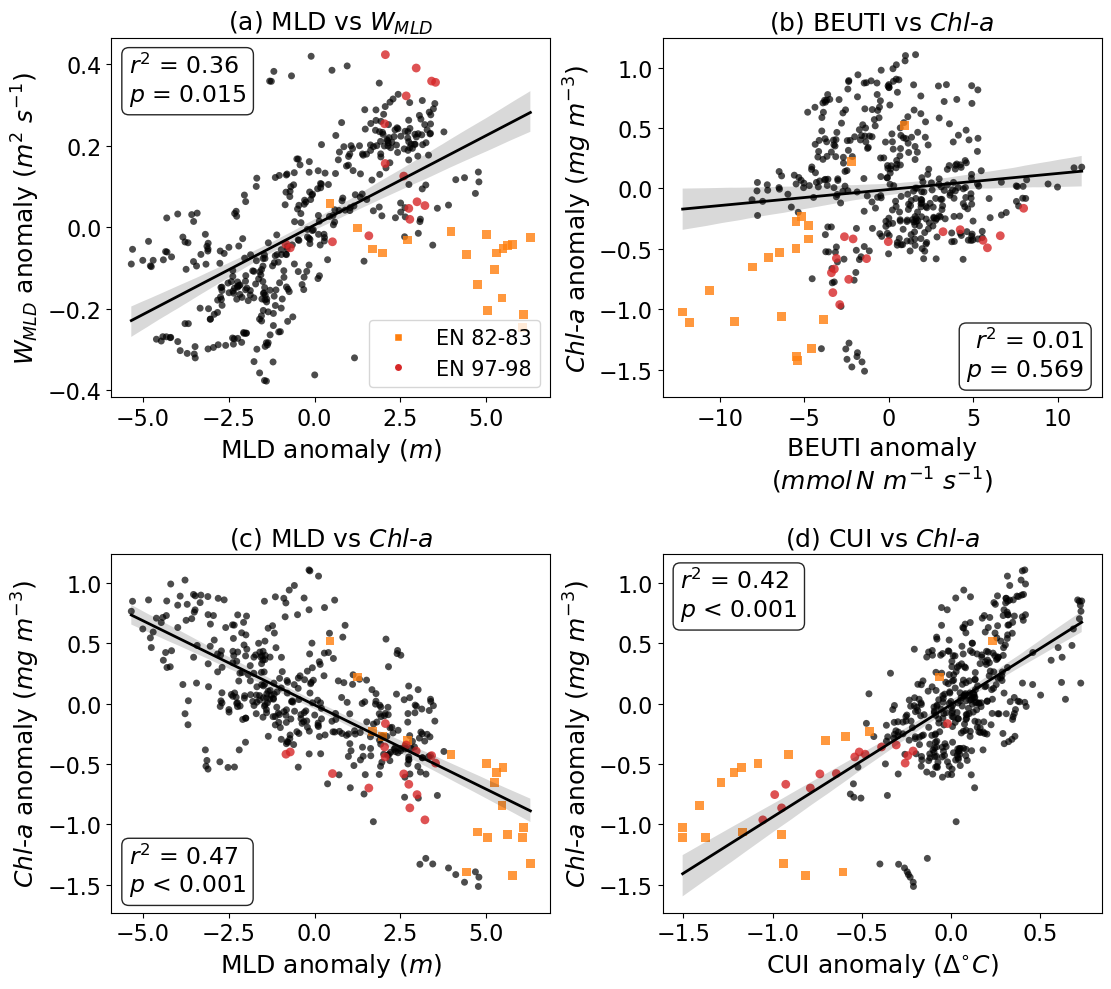

In [185]:
# ============================================================
# Same appendix figure, but the fit, r^2 and p now use ALL months, El Nino
# INCLUDED (ci_intervals with exclude_en=False). EN points keep their colours.
# 2x2 layout; panel (a) is MLD vs W_MLD, the rest are against Chl-a.
# ============================================================
MLD_ts = MLD.MLD.mean(dim=('lat', 'lon'))
CHL_ts = CHL.chla.mean(dim=('lat', 'lon'))       # as in the Chl-a vs MLD / U^Ek cell below
CHL_LABEL = anom_label(TITLE_LABELS['Chl'], UNITS['Chl'])

# (tag, title, x series, x label, y series, y label)
panels_2x2 = [
    ('a', r'MLD vs $W_{MLD}$', MLD_ts, anom_label('MLD', '$m$'),
     WMLD_ts, REF_LABEL),
    ('b', r'BEUTI vs $Chl\text{-}a$', BEUTI.mean(dim='lat_band'), anom_label('BEUTI', UNITS['BEUTI']),
     CHL_ts, CHL_LABEL),
    ('c', r'MLD vs $Chl\text{-}a$', MLD_ts, anom_label('MLD', '$m$'),
     CHL_ts, CHL_LABEL),
    ('d', r'CUI vs $Chl\text{-}a$', CUI.CUI_cc.mean('lat'), anom_label('CUI', UNITS['CUI']),
     CHL_ts, CHL_LABEL),
]

# r^2 / p box position per panel (default upper left)
BOX_POS = {'b': (0.96, 0.04, 'bottom', 'right'),   # lower right
           'c': (0.04, 0.04, 'bottom', 'left')}    # lower left

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
fig.get_layout_engine().set(h_pad=0.15)   # extra breathing room between rows
axs = axs.flatten()

for ax, (tag, title, X, xlabel, Y, ylabel) in zip(axs, panels_2x2):
    res, x, y, en1, en2 = ia_pair(X, Y, exclude_en=False)
    non_en = ~(en1 | en2)

    ax.scatter(x[non_en], y[non_en], c='black', marker='o',
               edgecolors='none', s=25, alpha=0.7, label='Non-EN')
    ax.scatter(x[en1], y[en1], c='tab:orange', marker='s',
               edgecolors='none', s=40, alpha=0.8, label='EN 1982-83')
    ax.scatter(x[en2], y[en2], c='tab:red', marker='o',
               edgecolors='none', s=40, alpha=0.8, label='EN 1997-98')

    # fit on ALL months (EN included)
    sns.regplot(x=x, y=y, ax=ax, ci=95, scatter=False,
                line_kws={'color': 'black', 'lw': 2})

    tx, ty, va, ha = BOX_POS.get(tag, (0.04, 0.96, 'top', 'left'))
    ax.text(tx, ty, rp_label(res),
            transform=ax.transAxes, va=va, ha=ha, fontsize=11 + lsz,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    ax.set_xlabel(xlabel, fontsize=12 + lsz)
    ax.set_ylabel(ylabel, fontsize=12 + lsz)
    ax.set_title(f"({tag}) {title}", fontsize=12 + lsz)
    ax.tick_params(labelsize=10 + lsz)

    print_res(f'({tag}) all months', res)

# the three Chl-a panels (b, c, d) share their y-axis; (a) has its own units
for ax in axs[2:4]:
    ax.sharey(axs[1])

axs[0].legend(handles=[
    Line2D([0], [0], marker='s', color='w', markerfacecolor='tab:orange',
           markersize=6, label='EN 82-83'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red',
           markersize=6, label='EN 97-98'),
], loc='lower right', frameon=True, fontsize=9 + lsz)

# plt.savefig('Figures/Bio_upwelling.pdf',
#             bbox_inches='tight', dpi=300)
plt.show()

### CUI vs MLD and CUI / $W_{MLD}$ vs MLD (from `Bio_response_upwelling`)

a) MLD vs CUI (all months)   r = -0.616  95% CI = [-0.79, -0.34]  r2 = 0.38  p = 0.00017  N = 420  N_eff = 32.1
b) MLD vs CUI_per_W_MLD (all months) r = -0.794  95% CI = [-0.90, -0.60]  r2 = 0.63  p = 3.4e-07  N = 420  N_eff = 28.6


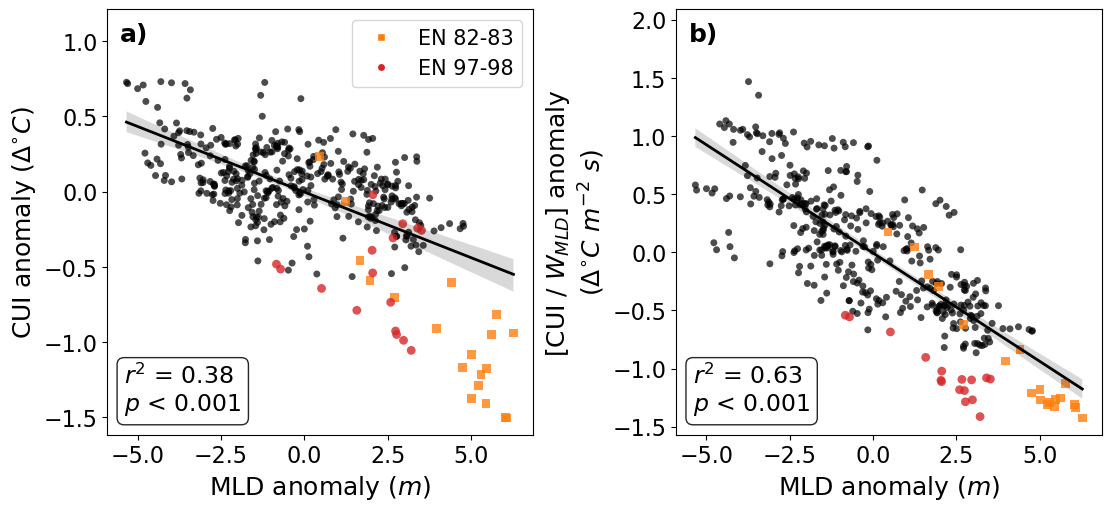

In [186]:
# ============================================================
# a) CUI vs MLD and b) CUI / W_MLD vs MLD (from Bio_response_upwelling),
# with the ci_intervals treatment: detrended 13-month anomalies, fit, r^2 and
# p (N_eff) over ALL months (El Nino included, coloured).
# The ratio is taken from the FULL monthly values, then treated as a series
# (dividing anomalies would blow up where the W_MLD anomaly crosses zero).
# ============================================================
CUI_ts   = _to_series(CUI.CUI_cc.mean('lat'), 'CUI')
WMLD_m   = _to_series(WMLD_ts, 'W_MLD')            # month-start stamps, so they divide
RATIO_ts = (CUI_ts / WMLD_m).rename('CUI_per_W_MLD')
MLD_ts   = MLD.MLD.mean(dim=('lat', 'lon'))

panels_cui = [
    ('a', CUI_ts,   anom_label('CUI', UNITS['CUI'])),
    # unit on its own line, written out here so it does not depend on UNIT_NEWLINE
    ('b', RATIO_ts, r'[CUI / $W_{MLD}$] anomaly' + '\n' + r'($\Delta ^{\circ}C \ m^{-2} \ s$)'),
]

fig, axs = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)

for ax, (tag, Y, ylabel) in zip(axs, panels_cui):
    res, x, y, en1, en2 = ia_pair(MLD_ts, Y, exclude_en=False)   # x = MLD, y = CUI (or ratio)
    non_en = ~(en1 | en2)

    ax.scatter(x[non_en], y[non_en], c='black', marker='o',
               edgecolors='none', s=25, alpha=0.7, label='Non-EN')
    ax.scatter(x[en1], y[en1], c='tab:orange', marker='s',
               edgecolors='none', s=40, alpha=0.8, label='EN 1982-83')
    ax.scatter(x[en2], y[en2], c='tab:red', marker='o',
               edgecolors='none', s=40, alpha=0.8, label='EN 1997-98')

    # fit on ALL months (EN included)
    sns.regplot(x=x, y=y, ax=ax, ci=95, scatter=False,
                line_kws={'color': 'black', 'lw': 2})

    ax.text(0.04, 0.04, rp_label(res),
            transform=ax.transAxes, va='bottom', ha='left', fontsize=11 + lsz,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

    ax.set_xlabel(anom_label('MLD', '$m$'), fontsize=12 + lsz)
    ax.set_ylabel(ylabel, fontsize=12 + lsz)
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + 0.15 * (y1 - y0))   # headroom so the panel letter clears the points
    ax.text(0.03, 0.97, f'{tag})', transform=ax.transAxes, va='top', ha='left',
            fontsize=12 + lsz, fontweight='bold')
    ax.tick_params(labelsize=10 + lsz)

    print_res(f'{tag}) MLD vs {Y.name} (all months)', res)

axs[0].legend(handles=[
    Line2D([0], [0], marker='s', color='w', markerfacecolor='tab:orange',
           markersize=6, label='EN 82-83'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red',
           markersize=6, label='EN 97-98'),
], loc='upper right', frameon=True, fontsize=9 + lsz)

plt.savefig('Figures/CUI_ratio_and_CUI_vs_MLD.pdf', bbox_inches='tight', dpi=300)   # v4: not saved
plt.show()


MLD vs $N_{\mathrm{MLD}}$
    seasonal   : r = 0.93, r2 = 0.87, p = 1.0e-05, n = 12
    interannual: r = -0.31, r2 = 0.09, p = 9.7e-02, N_eff = 30.1
$U^{\mathrm{Ek}}$ vs $N_{\mathrm{MLD}}$
    seasonal   : r = 0.99, r2 = 0.98, p = 7.8e-10, n = 12
    interannual: r = -0.44, r2 = 0.20, p = 6.5e-03, N_eff = 36.6


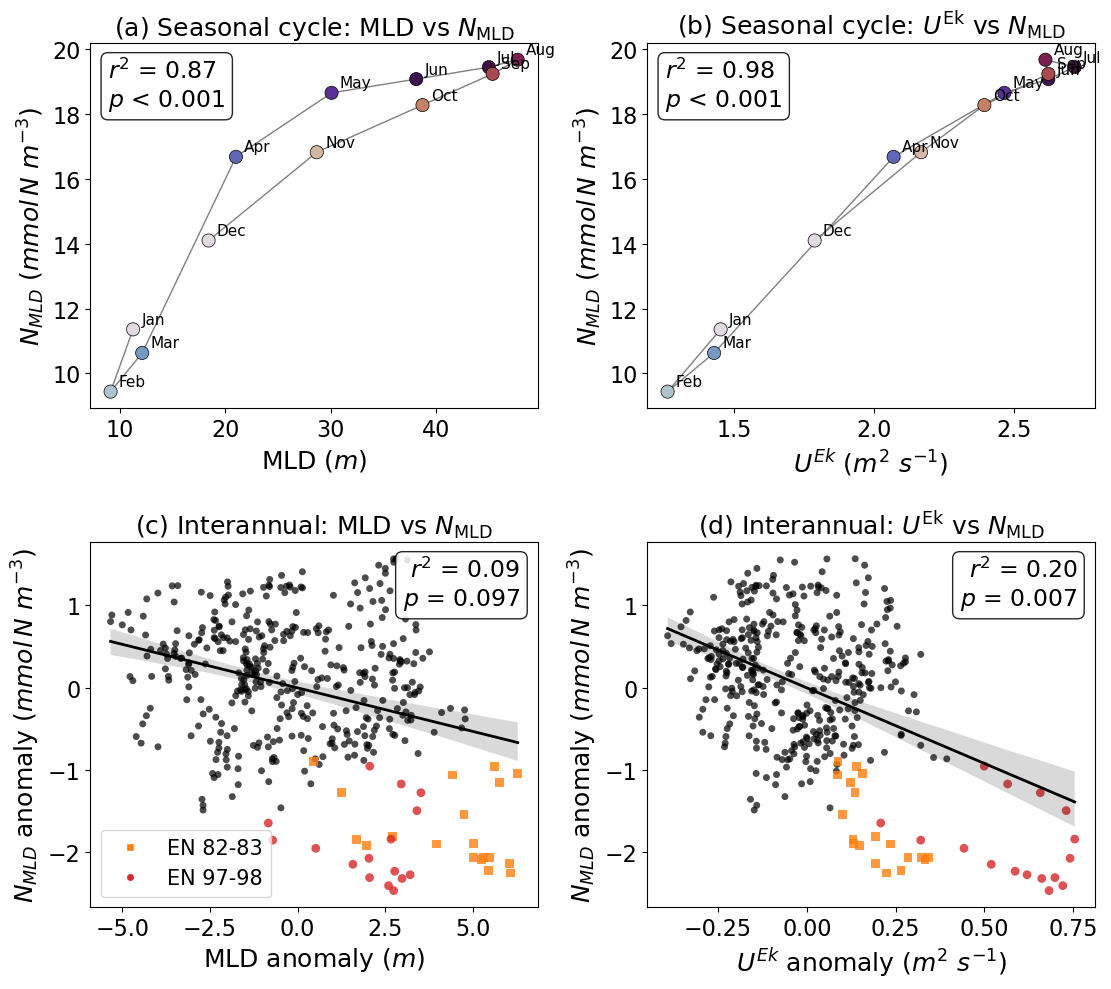

In [187]:
# ============================================================
# MLD vs N_MLD and U^Ek vs N_MLD, seasonally (top row) and interannually
# (bottom row).
#
# top row:    the two 12-month climatologies plotted against each other,
#             points coloured by month (n = 12, the series wraps Dec -> Jan).
# bottom row: detrended 13-month running-mean anomalies (ci_intervals), El Nino
#             months in orange (1982-83) / red (1997-98), fit, r^2 and p (N_eff)
#             over ALL months.
#
# U^Ek: offshore Ekman transport from the HR CUTI file (band mean, m2/s).
# ============================================================
N = xr.open_dataset('../data/Nitrogen.nc').compute()
N = N.where(N.TN_mld != 0, np.nan)
Nmask = coastal_band_mask(N, 'TN_mld', mask_km)
N = N.where(Nmask).sel(lon=slice(-85, None), lat=slice(-16, -5)).TN_mld
N['time'] = MLD.MLD.time            # same 432 monthly steps, different stamps

N_ts   = N.mean(dim=('lat', 'lon'))
MLD_ts = MLD.MLD.mean(dim=('lat', 'lon'))
UEK_ts = hr.U_ek.mean(dim='lat_band')

# seasonal (top row) labels: 'NAME (unit)'; interannual (bottom row): 'NAME anomaly (unit)'
N_UNIT = r'$mmol\,N \ m^{-3}$'
N_LABEL,   N_ALAB   = ax_label(r'$N_{MLD}$', N_UNIT, anom=False), anom_label(r'$N_{MLD}$', N_UNIT)
MLD_LABEL, MLD_ALAB = ax_label('MLD', '$m$', anom=False), anom_label('MLD', '$m$')
UEK_LABEL, UEK_ALAB = ax_label(r'$U^{Ek}$', UNITS['CUTI'], anom=False), anom_label(r'$U^{Ek}$', UNITS['CUTI'])

# seasonal climatology and interannual anomalies of the y-variable
Ns     = seasonality(N_ts)
N_full = prep_ia(N_ts)

MLDs_    = seasonality(MLD_ts)
MLD_full = prep_ia(MLD_ts)
UEKs_    = seasonality(UEK_ts)
UEK_full = prep_ia(UEK_ts)

# one column per x-variable: (title, seasonal axis label, seasonal cycle, anomalies, anomaly axis label)
cols = [
    (r'MLD vs $N_{\mathrm{MLD}}$',            MLD_LABEL, MLDs_, MLD_ts, MLD_ALAB),
    (r'$U^{\mathrm{Ek}}$ vs $N_{\mathrm{MLD}}$', UEK_LABEL, UEKs_, UEK_ts, UEK_ALAB),
]

months = np.arange(1, 13)

ia_stats = {}

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
fig.get_layout_engine().set(h_pad=0.15)

for j, (title, xlabel, xs_seas, xs_ts, xlabel_a) in enumerate(cols):
    ax_s, ax_i = axs[0, j], axs[1, j]
    tag_s, tag_i = 'ab'[j], 'cd'[j]

    # ---------------- seasonal (top row) ----------------
    xv, yv = xs_seas.values, Ns.values
    ax_s.scatter(xv, yv, c=months, cmap='twilight',
                 s=90, zorder=3, edgecolors='k', linewidths=0.5)
    ax_s.plot(xv, yv, color='grey', lw=1, zorder=2)
    for m, xm, ym in zip(months, xv, yv):
        ax_s.annotate(pd.Timestamp(2000, m, 1).strftime('%b'), (xm, ym),
                      textcoords='offset points', xytext=(6, 4),
                      fontsize=8 + lsz / 2)

    r_seas, p_seas = pearsonr(xv, yv)
    ax_s.text(0.04, 0.96, f"$r^2$ = {r_seas**2:.2f}\n{_ptxt(p_seas)}",
              transform=ax_s.transAxes, va='top', ha='left', fontsize=11 + lsz,
              bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax_s.set_xlabel(xlabel, fontsize=12 + lsz)
    ax_s.set_ylabel(N_LABEL, fontsize=12 + lsz)
    ax_s.set_title(f'({tag_s}) Seasonal cycle: {title}', fontsize=12 + lsz)
    ax_s.tick_params(labelsize=10 + lsz)

    # ---------------- interannual (bottom row) ----------------
    res, x, y, en1, en2 = ia_pair(xs_ts, N_ts, exclude_en=False)   # y = TN, x = MLD / U^Ek
    non_en = ~(en1 | en2)

    ax_i.scatter(x[non_en], y[non_en], c='black', marker='o',
                 edgecolors='none', s=25, alpha=0.7, label='Non-EN')
    ax_i.scatter(x[en1], y[en1], c='tab:orange', marker='s',
                 edgecolors='none', s=40, alpha=0.8, label='EN 1982-83')
    ax_i.scatter(x[en2], y[en2], c='tab:red', marker='o',
                 edgecolors='none', s=40, alpha=0.8, label='EN 1997-98')

    sns.regplot(x=x, y=y, ax=ax_i, ci=95, scatter=False,
                line_kws={'color': 'black', 'lw': 2})
    r_int, p_int = res['rho_hat'], res['p']

    ax_i.text(0.96, 0.96, f"$r^2$ = {r_int**2:.2f}\n{_ptxt(p_int)}",   # upper right
              transform=ax_i.transAxes, va='top', ha='right', fontsize=11 + lsz,
              bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax_i.set_xlabel(xlabel_a, fontsize=12 + lsz)
    ax_i.set_ylabel(N_ALAB, fontsize=12 + lsz)
    ax_i.set_title(f'({tag_i}) Interannual: {title}',
                   fontsize=12 + lsz)
    ax_i.tick_params(labelsize=10 + lsz)

    ia_stats[title] = (r_seas, p_seas, r_int, p_int, res['N_eff'])

axs[1, 0].legend(handles=[
    Line2D([0], [0], marker='s', color='w', markerfacecolor='tab:orange',
           markersize=6, label='EN 82-83'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red',
           markersize=6, label='EN 97-98'),
], loc='lower left', frameon=True, fontsize=9 + lsz)

for name, (r_seas, p_seas, r_int, p_int, n) in ia_stats.items():
    print(name)
    print(f"    seasonal   : r = {r_seas:.2f}, r2 = {r_seas**2:.2f}, "
          f"p = {p_seas:.1e}, n = 12")
    print(f"    interannual: r = {r_int:.2f}, r2 = {r_int**2:.2f}, "
          f"p = {p_int:.1e}, N_eff = {n:.1f}")

# the time-series cell below reuses the MLD pairing
r_s, p_s, r_i, p_i, _ = ia_stats[cols[0][0]]

# plt.savefig('Figures/paper/N_vs_MLD_Uek.pdf', bbox_inches='tight', dpi=300)
plt.show()


MLD vs $Chl\text{-}a$
    seasonal   : r = -0.94, r2 = 0.89, p = 5.0e-06, n = 12
    interannual: r = -0.69, r2 = 0.47, p = 4.6e-05, N_eff = 28.6
$U^{\mathrm{Ek}}$ vs $Chl\text{-}a$
    seasonal   : r = -0.85, r2 = 0.72, p = 4.8e-04, n = 12
    interannual: r = -0.43, r2 = 0.18, p = 1.0e-02, N_eff = 35.0


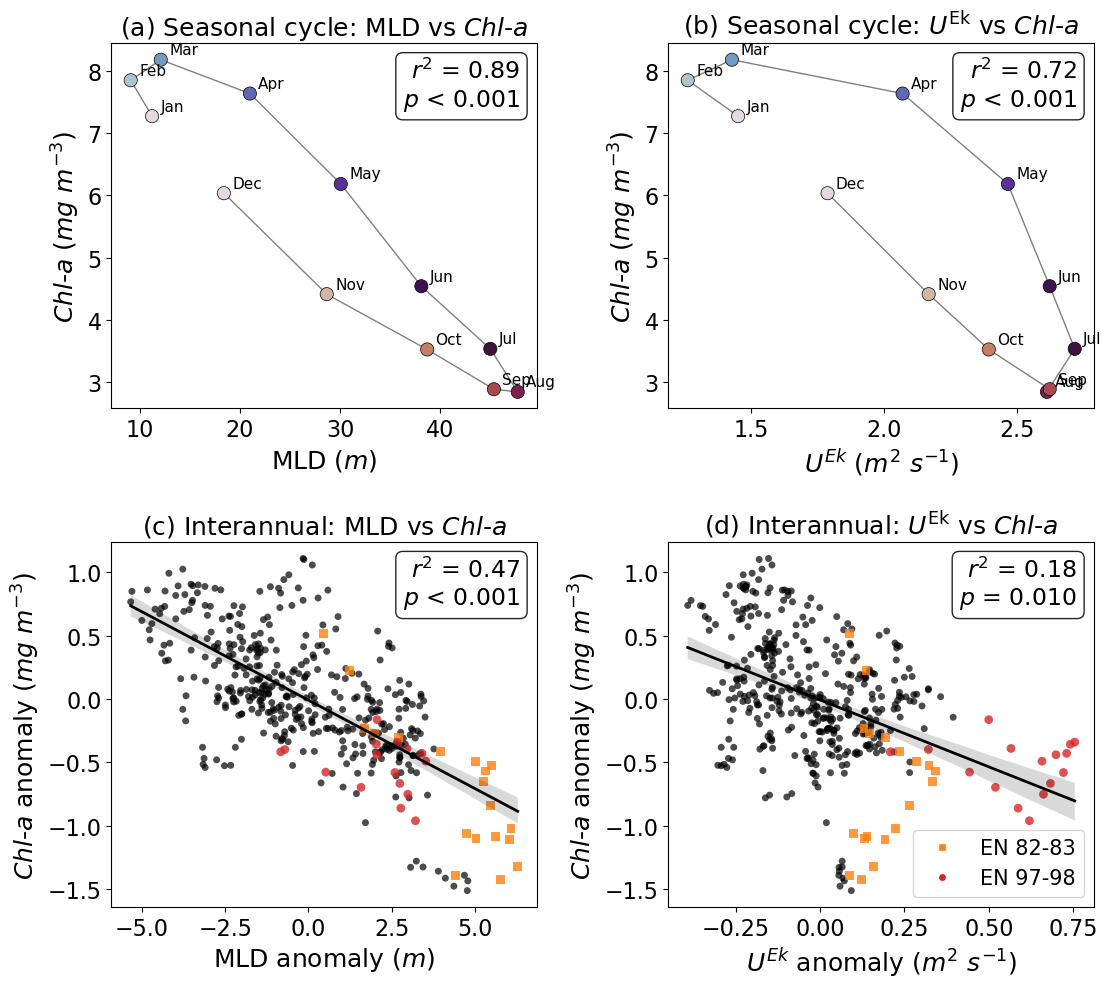

In [188]:
# ============================================================
# Same panels as for nitrogen, but with Chl-a as the response:
# MLD vs Chl-a (left) and U^Ek vs Chl-a (right).
#
# top row:    12-month climatologies plotted against each other, points
#             coloured by month (the series wraps Dec -> Jan).
# bottom row: detrended 13-month running-mean anomalies (ci_intervals), El Nino
#             months in orange (1982-83) / red (1997-98), fit, r^2 and p (N_eff)
#             over ALL months.
# ============================================================
CHL_ts = CHL.chla.mean(dim=('lat', 'lon'))

CHLs_    = seasonality(CHL_ts)
CHL_LAB  = ax_label(TITLE_LABELS['Chl'], UNITS['Chl'], anom=False)   # seasonal (top row)
CHL_ALAB = anom_label(TITLE_LABELS['Chl'], UNITS['Chl'])            # interannual (bottom row)

cols_chl = [
    (r'MLD vs $Chl\text{-}a$',                MLD_LABEL, MLDs_, MLD_ts, MLD_ALAB),
    (r'$U^{\mathrm{Ek}}$ vs $Chl\text{-}a$', UEK_LABEL, UEKs_, UEK_ts, UEK_ALAB),
]

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
fig.get_layout_engine().set(h_pad=0.15)

for j, (title, xlabel, xs_seas, xs_ts, xlabel_a) in enumerate(cols_chl):
    ax_s, ax_i = axs[0, j], axs[1, j]
    tag_s, tag_i = 'ab'[j], 'cd'[j]

    # ---------------- seasonal (top row) ----------------
    xv, yv = xs_seas.values, CHLs_.values

    ax_s.scatter(xv, yv, c=months, cmap='twilight',
                 s=90, zorder=3, edgecolors='k', linewidths=0.5)
    ax_s.plot(xv, yv, color='grey', lw=1, zorder=2)
    for m, xm, ym in zip(months, xv, yv):
        ax_s.annotate(pd.Timestamp(2000, m, 1).strftime('%b'), (xm, ym),
                      textcoords='offset points', xytext=(6, 4),
                      fontsize=8 + lsz / 2)

    r_seas, p_seas = pearsonr(xv, yv)
    ax_s.text(0.96, 0.96, f"$r^2$ = {r_seas**2:.2f}\n{_ptxt(p_seas)}",
              transform=ax_s.transAxes, va='top', ha='right', fontsize=11 + lsz,
              bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax_s.set_xlabel(xlabel, fontsize=12 + lsz)
    ax_s.set_ylabel(CHL_LAB, fontsize=12 + lsz)
    ax_s.set_title(f'({tag_s}) Seasonal cycle: {title}', fontsize=12 + lsz)
    ax_s.tick_params(labelsize=10 + lsz)

    # ---------------- interannual (bottom row) ----------------
    res, x, y, en1, en2 = ia_pair(xs_ts, CHL_ts, exclude_en=False)   # y = Chl-a, x = MLD / U^Ek
    non_en = ~(en1 | en2)

    ax_i.scatter(x[non_en], y[non_en], c='black', marker='o',
                 edgecolors='none', s=25, alpha=0.7, label='Non-EN')
    ax_i.scatter(x[en1], y[en1], c='tab:orange', marker='s',
                 edgecolors='none', s=40, alpha=0.8, label='EN 1982-83')
    ax_i.scatter(x[en2], y[en2], c='tab:red', marker='o',
                 edgecolors='none', s=40, alpha=0.8, label='EN 1997-98')

    sns.regplot(x=x, y=y, ax=ax_i, ci=95, scatter=False,
                line_kws={'color': 'black', 'lw': 2})
    r_int, p_int = res['rho_hat'], res['p']

    ax_i.text(0.96, 0.96, f"$r^2$ = {r_int**2:.2f}\n{_ptxt(p_int)}",
              transform=ax_i.transAxes, va='top', ha='right', fontsize=11 + lsz,
              bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))
    ax_i.set_xlabel(xlabel_a, fontsize=12 + lsz)
    ax_i.set_ylabel(CHL_ALAB, fontsize=12 + lsz)
    ax_i.set_title(f'({tag_i}) Interannual: {title}',
                   fontsize=12 + lsz)
    ax_i.tick_params(labelsize=10 + lsz)

    print(title)
    print(f"    seasonal   : r = {r_seas:.2f}, r2 = {r_seas**2:.2f}, "
          f"p = {p_seas:.1e}, n = 12")
    print(f"    interannual: r = {r_int:.2f}, r2 = {r_int**2:.2f}, "
          f"p = {p_int:.1e}, N_eff = {res['N_eff']:.1f}")

axs[1, 1].legend(handles=[
    Line2D([0], [0], marker='s', color='w', markerfacecolor='tab:orange',
           markersize=6, label='EN 82-83'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='tab:red',
           markersize=6, label='EN 97-98'),
], loc='lower right', frameon=True, fontsize=9 + lsz)

# plt.savefig('Figures/paper/Chl_vs_MLD_Uek.pdf',
#             bbox_inches='tight', dpi=300)
plt.show()


## Correlation with W_MLD during the El Niño months only

Same series as `ci_intervals` (anomalies → detrend → 13-month running mean, all months), restricted to the El Niño months (06/1982–12/1983, 04/1997–07/1998, no pad).

Each event is only 16–19 smoothed months, too short for `acf_gaps` / N_eff, so no CI is given. The **p-value comes from a phase-randomisation surrogate test** (Ebisuzaki, 1997):

1. the full-record smoothed index series (all months) is Fourier transformed, its phases randomised and transformed back → same power spectrum, i.e. the same autocorrelation, but no relation to W_MLD;
2. r with W_MLD is computed over the same El Niño months for each of `N_SURR` surrogates;
3. p = fraction of surrogates with |r| ≥ |r_obs| (two-sided).

The autocorrelation is thus taken from the whole record, not from the short event.

In [189]:
# ============================================================
# W_MLD vs each index, El Nino months ONLY (X = W_MLD, Y = index)
# r, r^2 and a phase-randomisation p-value (Ebisuzaki 1997)
# ============================================================
N_SURR = 10000
rng = np.random.default_rng(42)


def phase_surrogates(y, n_surr, rng):
    # surrogates of y with the same amplitude spectrum (same ACF), random phases
    y = np.asarray(y, float)
    F = np.fft.rfft(y - y.mean())
    ph = rng.uniform(0, 2 * np.pi, (n_surr, F.size))
    ph[:, 0] = 0                              # keep the mean term real
    if y.size % 2 == 0:
        ph[:, -1] = 0                         # keep the Nyquist term real
    return np.fft.irfft(np.abs(F) * np.exp(1j * ph), n=y.size) + y.mean()


def _corr_rows(a, B):
    # Pearson r of vector a with every row of B
    a = a - a.mean()
    B = B - B.mean(axis=1, keepdims=True)
    return (B @ a) / (np.sqrt((a ** 2).sum()) * np.sqrt((B ** 2).sum(axis=1)))


rows = []
for yname, Y in ia_indices.items():
    res, x, y, en1, en2 = ia_pair(WMLD_ts, Y, exclude_en=False)
    y_surr = phase_surrogates(y, N_SURR, rng)
    for ev, m in [('EN 1982-83', en1), ('EN 1997-98', en2), ('both EN', en1 | en2)]:
        r = float(np.corrcoef(x[m], y[m])[0, 1])
        r_surr = _corr_rows(x[m], y_surr[:, m])
        p = (1 + np.sum(np.abs(r_surr) >= abs(r))) / (N_SURR + 1)
        rows.append(dict(y=yname, months=ev, N=int(m.sum()), r=r, R2=r ** 2,
                         r95_surr=np.quantile(np.abs(r_surr), 0.95), p=p))

en_table = pd.DataFrame(rows).round({'r': 3, 'R2': 2, 'r95_surr': 2, 'p': 3})
print('=== W_MLD vs index, El Nino months only (detrended 13-month smoothed anomalies) ===')
print(f'p: phase-randomisation test, {N_SURR} surrogates; r95_surr = |r| needed for p < 0.05')
en_table

=== W_MLD vs index, El Nino months only (detrended 13-month smoothed anomalies) ===
p: phase-randomisation test, 10000 surrogates; r95_surr = |r| needed for p < 0.05


,y,months,N,r,R2,r95_surr,p
0,CUTI,EN 1982-83,19,0.920,0.85,0.76,0.001
1,CUTI,EN 1997-98,16,0.966,0.93,0.95,0.021
2,CUTI,both EN,35,0.903,0.82,0.84,0.010
3,U_ek,EN 1982-83,19,-0.126,0.02,0.77,0.882
4,U_ek,EN 1997-98,16,0.498,0.25,0.97,0.774
5,U_ek,both EN,35,0.709,0.50,0.85,0.199
6,BEUTI,EN 1982-83,19,0.928,0.86,0.76,0.000
7,BEUTI,EN 1997-98,16,0.972,0.95,0.96,0.018
8,BEUTI,both EN,35,0.966,0.93,0.84,0.000
9,CUI,EN 1982-83,19,0.782,0.61,0.78,0.047


In [190]:
# ============================================================
# RMSE of U^Ek and CUTI against W_MLD, El Nino months only (both events),
# on the same detrended 13-month smoothed anomalies as en_table.
#   RMSE           = sqrt(mean((index - W_MLD)^2)), m2/s
#   RMSE reduction = (RMSE_Uek - RMSE_CUTI) / RMSE_Uek
# ============================================================
rmse_en = {}
for name in ['U_ek', 'CUTI']:
    res, x, y, en1, en2 = ia_pair(WMLD_ts, ia_indices[name], exclude_en=False)
    m = en1 | en2
    rmse_en[name] = float(np.sqrt(np.mean((y[m] - x[m]) ** 2)))
    r2 = en_table.query("y == @name and months == 'both EN'").R2.item()
    print(f'{name:5s} both EN:  r2 = {r2:.2f}   RMSE = {rmse_en[name]:.3f} m2/s   N = {m.sum()}')
print(f'-> CUTI reduces the RMSE by '
      f'{100 * (rmse_en["U_ek"] - rmse_en["CUTI"]) / rmse_en["U_ek"]:.0f}% relative to U_ek')


U_ek  both EN:  r2 = 0.50   RMSE = 0.383 m2/s   N = 35
CUTI  both EN:  r2 = 0.82   RMSE = 0.121 m2/s   N = 35
-> CUTI reduces the RMSE by 68% relative to U_ek


In [191]:
# ============================================================
# Are the CUI minima during the two El Ninos the most negative of the record?
# Detrended 13-month smoothed anomalies (as in the combined figure, panel a).
# Lists the 5 deepest separate minima (at least 12 months apart).
# ============================================================
cui_ia = prep_ia(CUI.CUI_cc.mean('lat')).dropna('time')
order  = np.argsort(cui_ia.values)
picked = []
for k in order:
    t = cui_ia.time.values[k]
    if all(abs((t - q).astype('timedelta64[D]').astype(int)) > 365 for q in picked):
        picked.append(t)
        print(f"{str(t)[:7]}   CUI anomaly = {float(cui_ia[k]):+.2f} degC"
              f"   EN: {bool(np.asarray(_en_mask(cui_ia.time[k:k+1]))[0])}")
    if len(picked) == 5:
        break


1983-01   CUI anomaly = -1.50 degC   EN: True
1997-09   CUI anomaly = -1.05 degC   EN: True
1991-12   CUI anomaly = -0.47 degC   EN: False
2002-08   CUI anomaly = -0.37 degC   EN: False
2014-11   CUI anomaly = -0.33 degC   EN: False


## Table 2

Non-extreme: `ci_intervals`, El Niño excluded (no pad), r with 95% CI (N_eff). Extreme El Niño: r over both events (phase-randomisation test), shown if p < 0.05, else NS.

In [192]:
# ============================================================
# Table 2 built from the results above
# ============================================================
TABLE_ROWS = [('CUTI', 'CUTI'), ('BEUTI', 'BEUTI'), ('CUI', 'CUI'), ('Chl-a', 'Chl-a')]
en_both = en_table[en_table['months'] == 'both EN'].set_index('y')

rows = []
for key, label in TABLE_ROWS:
    res = ci_intervals(WMLD_ts, ia_indices[key], pad_months=PAD, exclude_en=True)
    r_en, p_en = en_both.loc[key, 'r'], en_both.loc[key, 'p']
    rows.append({'index': label,
                 'r non-extreme': round(res['rho_hat'], 2),
                 '95% CI': f"[{res['ci_low']:+.2f}, {res['ci_high']:+.2f}]",
                 'r extreme El Niño': f'{r_en:+.2f}' if p_en < 0.05 else 'NS',
                 'p extreme El Niño': p_en})

table2 = pd.DataFrame(rows).set_index('index')
table2


,r non-extreme,95% CI,r extreme El Niño,p extreme El Niño
index,,,,
CUTI,0.88,"[+0.74, +0.95]",+0.90,0.010
BEUTI,0.85,"[+0.68, +0.93]",+0.97,0.000
CUI,-0.06,"[-0.40, +0.29]",NS,0.157
Chl-a,-0.43,"[-0.68, -0.08]",NS,0.486


In [193]:
# Seasonal cycle: descriptive r of the 12 monthly climatology points
seas = {k: seasonality(ia_indices[k]) for k in ['CUI', 'BEUTI', 'Chl-a']}
for a, b in [('CUI', 'BEUTI'), ('BEUTI', 'Chl-a')]:
    r_seas = np.corrcoef(seas[a].values, seas[b].values)[0, 1]
    print(f"{a} vs {b} (seasonal cycle): r = {r_seas:.3f}, n = {seas[a].sizes['month']}")


CUI vs BEUTI (seasonal cycle): r = -0.064, n = 12
BEUTI vs Chl-a (seasonal cycle): r = -0.838, n = 12
